# Pricing Jasper Vault's Perpetual Protect (PP)

Team notebook for the DBA5102 Blockchain Group Assignment, Option 2. Built by Aman from the converged team plan
(`aman/PLAN.md`, Aman + Maksim, 15 Oct 2026). It runs top to bottom from saved files, with no internet.

**The idea.** A market-fitted *fair value* (the expected payout of each order, a design taken from our teammate
Maksim's model) decides which orders should cost more or less. Our *estimate of Jasper Vault's current price* sets the
overall level and the per-order limits. Prices never go below fair value.

**How to run.** From the repository root: `aman/.venv/bin/jupyter nbconvert --to notebook --execute --inplace aman/pp_pricing.ipynb`
(set up the environment with `uv venv --python 3.12 aman/.venv` and `uv pip install --python aman/.venv/bin/python -r aman/requirements.txt`).
The snapshots in `aman/data_external/` come from `aman/fetch_external.py`.

**Status (16 Oct): final.** Team decision at the 16 Oct regroup: model F1, theta_level = 0, band 0.8-1.2. The
specification was locked at 2026-10-16 04:46 SGT (section 11); sections 12-13 are report-only risk tables, and section 14 is the
544-row reference check, run after the lock.

## 1. Setup

Fixed package versions and a fixed random seed make every number in this notebook reproducible. All money is in USDC.
Time is UTC everywhere except the time-of-day profile, which follows New York time because US trading hours drive BTC's
intraday volatility.

In [1]:
import platform
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels

SEED = 2026
pd.set_option("display.width", 160, "display.max_columns", 30)

AMAN = Path.cwd() if (Path.cwd() / "PLAN.md").exists() else Path.cwd() / "aman"
REPO = next((p for p in AMAN.resolve().parents if (p / 'data' / 'with_base_premium').is_dir()), AMAN.parent)  # code_final path fix
TRAIN_CSV = REPO / "data/with_base_premium/pp_transactions_training.csv"
BLIND_CSV = REPO / "data/validation/pp_transactions_validation.csv"
CANDLES_CSV = REPO / "data/validation/btc_market_history.csv"
EXT = AMAN / "data_external"

ATM = 1 / np.sqrt(2 * np.pi)            # 0.3989: an ATM option's price per unit of sigma * sqrt(T)
YEAR_S = 365 * 24 * 3600                # BTC trades 24/7
YEAR_MIN = 365 * 24 * 60
DURATIONS_S = [1800, 3600, 7200, 14400, 28800, 43200, 86400]
TRAIL_MIN = [60, 240, 1440, 10080]      # trailing windows: 1 hour, 4 hours, 1 day, 1 week
CORE_EVENTS = ["CPI", "NFP", "FOMC"]
EVENT_WINDOW_MIN = 30
FINAL_CUTOFF = pd.Timestamp("2026-07-31 17:11:00")

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__}")

Python 3.12.14 | numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1 | statsmodels 0.15.0 | matplotlib 3.11.2


## 2. Orders

Two order files: the training file (7,204 orders, February to July, with payouts) and the blind file Jasper Vault (JV)
will score us on (4,155 orders, 31 July to 14 October, payouts hidden). The blind file mixes two timestamp formats, so
one parser handles both. There is no order ID, so we keep each file's row position as the key.

In [2]:
def parse_times(s):
    # Both formats in the files: '2026-08-24 16:05:59' and the minute-only '2026/7/31 17:11'.
    full = pd.to_datetime(s, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    short = pd.to_datetime(s, format="%Y/%m/%d %H:%M", errors="coerce")
    return full.fillna(short).astype("datetime64[ns]")


def load_orders(path):
    d = pd.read_csv(path)
    for c in ["createdAt", "closedAt", "expirationDate"]:
        d[c] = parse_times(d[c])
    assert d.createdAt.notna().all(), f"unparseable createdAt in {path.name}"
    d["row"] = np.arange(len(d))                                    # position in the original file
    d["T_years"] = d.productType / YEAR_S
    d["notional"] = d.quantity_BTC * d.strikePrice                  # q x K, USDC
    d["scale"] = ATM * d.notional * np.sqrt(d.T_years)              # USDC per 1.00 of annual volatility
    d["base_usd"] = d.quantity_BTC * d.apiBasePrice_per_BTC_USDC    # B; NaN when there is no base quote
    d["month"] = d.createdAt.dt.strftime("%Y-%m")
    d["day"] = d.createdAt.dt.floor("D")
    return d


train = load_orders(TRAIN_CSV)
blind = load_orders(BLIND_CSV)
lab = train[train.realizedProfit_USDC.notna()].copy()               # resolved orders: the only labels we have
print(f"training {len(train):,} orders ({len(lab):,} resolved) | blind {len(blind):,} orders")

training 7,204 orders (7,150 resolved) | blind 4,155 orders


### 2.1 Checks before trusting the pipeline

These numbers were verified earlier by two separate scripts (`aman/checks/`). If any of them moves, the data or the
loading code has changed, so the notebook stops. The volatility ladder puts the base price, JV's price and the payouts on
one ruler: any USDC amount on a group of orders implies a volatility, `sigma = sum(amount) / sum(0.3989 x q x K x sqrt(T))`
(Black & Scholes, 1973, for short at-the-money options).

In [3]:
def check_row(name, got, want, tol):
    return {"check": name, "value": round(float(got), 4), "expected": want, "ok": abs(float(got) - float(want)) <= tol}


def implied_vol(amount, g):
    # Any USDC amount on a group of orders, expressed as an annual volatility.
    return amount.sum() / g.scale.sum()


hb = lab[lab.base_usd.notna()]
LR = lab.realizedProfit_USDC.sum() / lab.premiumAmount_USDC.sum()
checks = pd.DataFrame([
    check_row("orders in training file", len(train), 7204, 0),
    check_row("resolved orders (54 unresolved dropped)", len(lab), 7150, 0),
    check_row("premium, USDC", lab.premiumAmount_USDC.sum(), 248089, 1),
    check_row("payouts, USDC", lab.realizedProfit_USDC.sum(), 230652, 1),
    check_row("loss ratio", LR, 0.930, 0.0005),
    check_row("margin", 1 - LR, 0.070, 0.0005),
    check_row("orders without a base price", train.base_usd.isna().sum(), 1131, 0),
    check_row("resolved orders with a base price", len(hb), 6019, 0),
    check_row("loss ratio at base x 1.00", hb.realizedProfit_USDC.sum() / hb.base_usd.sum(), 1.403, 0.0005),
    check_row("base vol", implied_vol(hb.base_usd, hb), 0.343, 0.0005),
    check_row("charged vol", implied_vol(hb.premiumAmount_USDC, hb), 0.494, 0.0005),
    check_row("needed vol (break-even)", implied_vol(hb.realizedProfit_USDC, hb), 0.481, 0.0005),
])
print(checks.to_string(index=False))
assert checks.ok.all(), "a verified number moved: stop and investigate"


                                  check       value   expected   ok
                orders in training file   7204.0000   7204.000 True
resolved orders (54 unresolved dropped)   7150.0000   7150.000 True
                          premium, USDC 248089.0051 248089.000 True
                          payouts, USDC 230652.0530 230652.000 True
                             loss ratio      0.9297      0.930 True
                                 margin      0.0703      0.070 True
            orders without a base price   1131.0000   1131.000 True
      resolved orders with a base price   6019.0000   6019.000 True
              loss ratio at base x 1.00      1.4028      1.403 True
                               base vol      0.3428      0.343 True
                            charged vol      0.4944      0.494 True
                needed vol (break-even)      0.4809      0.481 True


      orders   base  charged  needed
0.5h  2678.0  0.388    0.754   0.564
1h     487.0  0.365    0.586   0.556
2h     893.0  0.327    0.458   0.403
4h     954.0  0.332    0.440   0.513
8h     808.0  0.335    0.428   0.433
12h     46.0  0.300    0.436   0.353
24h    153.0  0.343    0.434   0.157


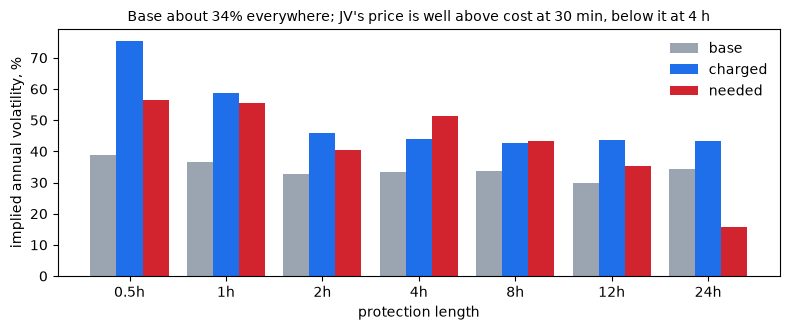

In [4]:
ladder = hb.groupby("productType").apply(lambda g: pd.Series({
    "orders": len(g), "base": implied_vol(g.base_usd, g), "charged": implied_vol(g.premiumAmount_USDC, g),
    "needed": implied_vol(g.realizedProfit_USDC, g)}), include_groups=False)
ladder.index = [f"{t / 3600:g}h" for t in ladder.index]
print(ladder.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(ladder))
for i, (col, colour) in enumerate([("base", "#9aa5b1"), ("charged", "#1f6feb"), ("needed", "#d1242f")]):
    ax.bar(x + (i - 1) * 0.27, ladder[col] * 100, width=0.27, label=col, color=colour)
ax.set_xticks(x, ladder.index)
ax.set_xlabel("protection length")
ax.set_ylabel("implied annual volatility, %")
ax.set_title("Base about 34% everywhere; JV's price is well above cost at 30 min, below it at 4 h", fontsize=10)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 2.2 Facts about the blind file

JV scores our prices on these orders against outcomes we cannot see. The file is two blocks joined together: rows
0-1,897 are the documented release (timestamps cut to the minute), rows 1,898-4,154 are newer orders. More than half
have no base price, so the model must price without one. `closedAt` is filled in even though it is an outcome, so it is
never an input.

**A limitation we cannot fix.** JV's guide says 627 training orders charged *below* the base were removed. The blind
file has no base for 2,195 orders, so the same filter cannot be applied or checked there. If JV sometimes discounts, an
estimate of its price learned from the filtered training data could run high on discounted blind orders. Missing bases
do not prove a discount, and we do not know the size or direction of any bias, so we state it and do not invent a
correction.

In [5]:
raw_blind = pd.read_csv(BLIND_CSV, dtype=str)
minute_only = raw_blind.createdAt.str.contains("/")
blind_facts = pd.DataFrame([
    check_row("blind orders", len(blind), 4155, 0),
    check_row("first createdAt = 2026-07-31 17:11", blind.createdAt.min() == pd.Timestamp("2026-07-31 17:11"), True, 0),
    check_row("last createdAt = 2026-10-14 02:46:18", blind.createdAt.max() == pd.Timestamp("2026-10-14 02:46:18"), True, 0),
    check_row("premium blank in every row", blind.premiumAmount_USDC.isna().all(), True, 0),
    check_row("order price blank in every row", blind.orderPrice_per_BTC_USDC.isna().all(), True, 0),
    check_row("payout blank in every row", blind.realizedProfit_USDC.isna().all(), True, 0),
    check_row("closedAt filled in every row (outcome: never an input)", blind.closedAt.notna().all(), True, 0),
    check_row("orders without a base price", blind.base_usd.isna().sum(), 2195, 0),
    check_row("minute-only timestamps", minute_only.sum(), 1898, 0),
    check_row("minute-only rows are exactly rows 0-1,897", (np.flatnonzero(minute_only) == np.arange(1898)).all(), True, 0),
    check_row("same 13 columns as training", list(raw_blind.columns) == list(pd.read_csv(TRAIN_CSV, nrows=0).columns), True, 0),
])
print(blind_facts.to_string(index=False))
assert blind_facts.ok.all()
by_block = blind.assign(block=np.where(blind.row < 1898, "A: rows 0-1,897", "B: rows 1,898-4,154")).groupby("block").agg(
    orders=("row", "size"), first=("createdAt", "min"), last=("createdAt", "max"),
    with_base=("base_usd", lambda s: int(s.notna().sum())), with_markup=("markup_per_BTC_USDC", lambda s: int(s.notna().sum())))
print(by_block.to_string())

                                                 check  value expected   ok
                                          blind orders 4155.0     4155 True
                    first createdAt = 2026-07-31 17:11    1.0     True True
                  last createdAt = 2026-10-14 02:46:18    1.0     True True
                            premium blank in every row    1.0     True True
                        order price blank in every row    1.0     True True
                             payout blank in every row    1.0     True True
closedAt filled in every row (outcome: never an input)    1.0     True True
                           orders without a base price 2195.0     2195 True
                                minute-only timestamps 1898.0     1898 True
             minute-only rows are exactly rows 0-1,897    1.0     True True
                           same 13 columns as training    1.0     True True
                     orders               first                last  with_base  with_mar

## 3. BTC candles and quote-time features

Every feature for an order uses only one-minute candles that **closed before** the order was created: the candle that
contains `createdAt` is still open, so the last usable one is the minute before (an as-of join). We index candles by minute
since 1 January 2026, which makes trailing sums one subtraction. Calendar arrays (time-of-day slot, release times) need no
prices, so they run two days past the last candle to cover 24-hour windows on the last blind orders.

In [6]:
def load_candles(path):
    c = pd.read_csv(path, usecols=["open_time_utc", "close_time_utc", "high", "low", "close", "volume"])
    c["open_time"] = pd.to_datetime(c.open_time_utc, format="%Y-%m-%dT%H:%M:%SZ").astype("datetime64[ns]")
    c["close_time"] = pd.to_datetime(c.close_time_utc, format="%Y-%m-%dT%H:%M:%S.%fZ").astype("datetime64[ns]")
    steps = c.open_time.diff().dropna().unique()
    assert len(steps) == 1 and steps[0] == pd.Timedelta("1min"), "candles are not a gap-free one-minute grid"
    return c


def load_releases(path, types=CORE_EVENTS):
    ev = pd.read_csv(path)
    ev = ev[ev.event_type.isin(types)].copy()
    ev["ts_utc"] = pd.to_datetime(ev.ts_utc).astype("datetime64[ns]")
    return ev.sort_values("ts_utc").reset_index(drop=True)


def minute_index(ts, t0):
    # Index of the one-minute candle that contains each timestamp.
    return ((pd.Series(ts).astype("datetime64[ns]") - t0) // pd.Timedelta("1min")).to_numpy().astype(np.int64)


def build_market(c, releases, extra_minutes=2 * 1440):
    t0 = c.open_time.iloc[0]
    logp = np.log(c.close.to_numpy())
    r = np.diff(logp, prepend=logp[0])                             # one-minute log returns
    n_cal = len(c) + extra_minutes
    ny = pd.date_range(t0, periods=n_cal, freq="min").tz_localize("UTC").tz_convert("America/New_York")
    bucket = np.asarray(ny.hour * 2 + ny.minute // 30 + 48 * (ny.dayofweek >= 5))   # 96 half-hour slots
    ev_idx = minute_index(releases.ts_utc, t0)
    ev_idx = ev_idx[(ev_idx >= 0) & (ev_idx < n_cal)]
    flags = np.zeros(n_cal)
    flags[ev_idx] = 1.0
    return {"t0": t0, "n": len(c), "logp": logp, "cum_r2": np.concatenate([[0.0], np.cumsum(r * r)]),
            "bucket": bucket, "event_idx": ev_idx, "event_cum": np.concatenate([[0.0], np.cumsum(flags)])}


candles = load_candles(CANDLES_CSV)
releases = load_releases(EXT / "macro_events_2026_checked.csv")
mkt = build_market(candles, releases)
print(f"{len(candles):,} candles, {candles.open_time.iloc[0]} -> {candles.open_time.iloc[-1]} | "
      f"{len(releases)} core releases ({', '.join(CORE_EVENTS)}), {releases.ts_utc.min():%d %b} -> {releases.ts_utc.max():%d %b}")

412,080 candles, 2026-01-01 00:00:00 -> 2026-10-14 03:59:00 | 27 core releases (CPI, NFP, FOMC), 09 Jan -> 28 Oct


### 3.1 Order features

Realised variance over the last 1 hour, 4 hours, 1 day and 1 week follows Maksim's engine and the multi-horizon idea of
Corsi (2009). The same quantities, annualised, give the realised volatilities the reference-price model uses. JV said its
overlay uses RSI and Bollinger bands but not on which bars, so we declare 15-minute bars with the textbook settings
(RSI 14, Bollinger 20 bars and 2 standard deviations), using completed bars only. A release flag marks orders whose
window contains a scheduled CPI, jobs-report or FOMC release: release times are known in advance, released numbers are
never used.

In [7]:
def last_closed_minute(created, mkt):
    return minute_index(created, mkt["t0"]) - 1                    # the candle containing createdAt is still open


def trailing_var(mkt, k, h):
    # Mean squared one-minute log return over the h minutes ending at minute k (inclusive).
    cum = mkt["cum_r2"]
    return np.maximum((cum[k + 1] - cum[k + 1 - h]) / h, 1e-12)


def release_in_window(mkt, k, t_min):
    # 1 if a scheduled release falls in minutes k+1 .. k+T (the protection window).
    ec = mkt["event_cum"]
    return ((ec[k + t_min + 1] - ec[k + 1]) > 0).astype(int)


def bar_indicators(mkt, bar=15, rsi_n=14, bb_n=20):
    # RSI (Wilder smoothing) and Bollinger %b on completed 15-minute bars aligned to the clock.
    n_bars = mkt["n"] // bar
    s = pd.Series(np.exp(mkt["logp"][bar - 1: n_bars * bar: bar]))    # close of each bar's last minute
    chg = s.diff()
    up = chg.clip(lower=0).ewm(alpha=1 / rsi_n, adjust=False).mean()
    down = (-chg).clip(lower=0).ewm(alpha=1 / rsi_n, adjust=False).mean()
    mid, sd = s.rolling(bb_n).mean(), s.rolling(bb_n).std(ddof=0)
    return (100 - 100 / (1 + up / down)).to_numpy(), ((s - (mid - 2 * sd)) / (4 * sd)).to_numpy()


def add_market_features(d, mkt, bars, bar=15):
    d = d.copy()
    k = last_closed_minute(d.createdAt, mkt)
    assert (k >= max(TRAIL_MIN)).all(), "an order is too early for the one-week window"
    d["k"] = k
    for h in TRAIL_MIN:
        d[f"log_var_{h}m"] = np.log(trailing_var(mkt, k, h))
    for name, h in [("rv_60", 60), ("rv_1d", 1440), ("rv_7d", 10080)]:
        d[name] = np.sqrt(trailing_var(mkt, k, h) * YEAR_MIN)          # annualised realised volatility
    b = (k + 1) // bar - 1                                               # last bar that finished by minute k
    d["rsi_15m"], d["pctb_15m"] = bars[0][b], bars[1][b]
    d["release_in_window"] = release_in_window(mkt, k, (d.productType // 60).to_numpy())
    d["tod_slot"] = mkt["bucket"][k + 1]                                 # New York half-hour slot (calendar only)
    return d


bars = bar_indicators(mkt)
train = add_market_features(train, mkt, bars)
blind = add_market_features(blind, mkt, bars)
lab = train[train.realizedProfit_USDC.notna()].copy()

# Cross-check the minute arithmetic with a pandas as-of join on candle close times (strictly before createdAt).
both = pd.concat([train[["createdAt", "k"]], blind[["createdAt", "k"]]], ignore_index=True)
right = pd.DataFrame({"close_time": candles.close_time, "candle": np.arange(len(candles))})
asof = pd.merge_asof(both.reset_index().sort_values("createdAt"), right, left_on="createdAt", right_on="close_time",
                     direction="backward", allow_exact_matches=False).set_index("index").sort_index()
gap = (asof.createdAt - asof.close_time).dt.total_seconds()
assert (asof.candle.to_numpy() == both.k.to_numpy()).all() and gap.max() <= 60
print(f"as-of join agrees on all {len(both):,} orders; largest gap {gap.max():.1f} s")
print(train.groupby("month")[["rv_60", "rv_1d", "rv_7d", "rsi_15m", "pctb_15m", "release_in_window"]].mean().round(3).to_string())

as-of join agrees on all 11,359 orders; largest gap 59.0 s
         rv_60  rv_1d  rv_7d  rsi_15m  pctb_15m  release_in_window
month                                                             
2026-02  0.775  0.665  0.687   50.155     0.523              0.004
2026-03  0.523  0.555  0.578   50.854     0.537              0.051
2026-04  0.470  0.413  0.400   52.747     0.569              0.055
2026-05  0.385  0.333  0.317   49.177     0.461              0.029
2026-06  0.531  0.494  0.490   47.690     0.452              0.037
2026-07  0.376  0.349  0.340   49.326     0.491              0.042


### 3.2 Time-of-day profile and release variance (fitted per fold in Phase 2)

Two pieces of Maksim's engine are learned from candles, so they belong inside each fold's training period: a 96-slot
time-of-day variance profile (48 New York half-hours, weekdays and weekends), and the extra variance a scheduled release
adds. Here we only define them; Phase 2 fits them separately for every cutoff. The profile leaves out the 30 minutes
after each release, so releases are not counted twice.

In [8]:
def fit_tod_profile(mkt, k_start, k_end):
    # Mean squared one-minute return per slot / overall mean, on minutes k_start..k_end (releases left out).
    keep = np.zeros(k_end + 1, dtype=bool)
    keep[k_start:] = True
    for e in mkt["event_idx"][mkt["event_idx"] <= k_end]:
        keep[e: e + EVENT_WINDOW_MIN] = False
    r2 = np.diff(mkt["cum_r2"])[: k_end + 1][keep]
    slot = mkt["bucket"][: k_end + 1][keep]
    profile = np.bincount(slot, weights=r2, minlength=96) / np.maximum(np.bincount(slot, minlength=96), 1) / r2.mean()
    return profile, np.concatenate([[0.0], np.cumsum(profile[mkt["bucket"]])])


def window_mean(cum_profile, k_start, k_end):
    # Average profile value over minutes k_start..k_end (inclusive).
    return (cum_profile[k_end + 1] - cum_profile[k_start]) / (k_end - k_start + 1)


def release_excess_var(mkt, k_end, control_days=28):
    # Per release before k_end: squared 30-min move after it, minus the average squared move over the same UTC
    # window on the preceding release-free weekdays (Maksim's estimator). Returns one excess value per release.
    w, lp, ec = EVENT_WINDOW_MIN, mkt["logp"], mkt["event_cum"]
    out = []
    for e in mkt["event_idx"][mkt["event_idx"] + w <= k_end]:
        k = e - 1
        ctrl = np.array([k - 1440 * d for d in range(1, control_days + 1) if k - 1440 * d >= 0])
        weekday = (mkt["t0"] + pd.to_timedelta(ctrl, unit="min")).dayofweek < 5
        quiet = ec[ctrl + w + 1] - ec[ctrl + 1] == 0
        ctrl = ctrl[weekday & quiet]
        out.append((lp[k + w] - lp[k]) ** 2 - np.mean((lp[ctrl + w] - lp[ctrl]) ** 2))
    return np.array(out)

print("defined: fit_tod_profile, window_mean, release_excess_var (no profile is fitted on the full history)")

defined: fit_tod_profile, window_mean, release_excess_var (no profile is fitted on the full history)


## 4. Teammates' saved outputs

The scorecard compares our model with Maksim's and Subham's on the same orders, using their **saved** historical outputs
(we do not re-run their training). `fetch_external.py` copied them at fixed commits, keeping training-period rows only.
Here we confirm that every saved row maps to the right training order, and which months each covers.

In [9]:
import json

TEAM = EXT / "teammates"
inventory = json.loads((TEAM / "inventory.json").read_text())


def check_mapping(snap):
    # Each saved row must point at the same training order: same time, length, size and strike.
    m = snap.merge(train, left_on="row_id", right_on="row", suffixes=("_theirs", ""))
    ok = len(m) == len(snap)
    if "createdAt_theirs" in m:
        ok &= bool((parse_times(m.createdAt_theirs) == m.createdAt).all())
    for c in ["productType", "quantity_BTC", "strikePrice"]:
        if f"{c}_theirs" in m:
            ok &= bool(np.allclose(m[f"{c}_theirs"], m[c]))
    if "fold" in m:
        ok &= bool((m.fold == m.month).all())                       # Subham's fold label = the order's month
    return ok, m


team_rows = []
for name, label in [("maksim_walk_forward", "Maksim: walk-forward, refit before each month"),
                    ("maksim_test_pre_june_fit", "Maksim: one fit before 1 June"),
                    ("subham_backtest_selected", "Subham: selected config, monthly folds")]:
    snap = pd.read_csv(TEAM / f"{name}.csv")
    ok, m = check_mapping(snap)
    team_rows.append({"output": label, "rows": len(snap), "maps_to_our_rows": ok,
                      "months": ", ".join(sorted(m.month.unique())), "resolved_only": bool(m.realizedProfit_USDC.notna().all())})
team_rows.append({"output": "Jay v3.2", "rows": 0, "maps_to_our_rows": False,
                  "months": "N/A: no row-level history on this data release", "resolved_only": False})
team_table = pd.DataFrame(team_rows)
print(team_table.to_string(index=False))
assert team_table.maps_to_our_rows.iloc[:3].all()

# Our market features reproduce the ones Maksim saved (same candles, same definitions).
mk = pd.read_csv(TEAM / "maksim_walk_forward.csv").merge(train, left_on="row_id", right_on="row", suffixes=("_mk", ""))
feat_diff = max(np.abs(mk[f"log_var_{h}m_mk"] - mk[f"log_var_{h}m"]).max() for h in TRAIL_MIN)
print(f"largest difference in log realised variance vs Maksim's saved features: {feat_diff:.1e}; "
      f"release flags agree on {np.mean(mk.event_in_window == mk.release_in_window):.1%} of orders")
print("prior exposure to validation material:", *inventory["prior_validation_exposure"], sep="\n - ")

                                       output  rows  maps_to_our_rows                                               months  resolved_only
Maksim: walk-forward, refit before each month  7150              True 2026-02, 2026-03, 2026-04, 2026-05, 2026-06, 2026-07           True
                Maksim: one fit before 1 June  4841              True                                     2026-06, 2026-07           True
       Subham: selected config, monthly folds  5806              True                            2026-05, 2026-06, 2026-07           True
                                     Jay v3.2     0             False       N/A: no row-level history on this data release          False


largest difference in log realised variance vs Maksim's saved features: 4.2e-11; release flags agree on 100.0% of orders
prior exposure to validation material:
 - Maksim: run_sealed_check.py and results/sealed_check/ rebuild validation-period payouts from candles; validation rows also appear in results/extensions/exposure_limits.csv and hedging_summary.csv
 - Subham: validation_premiums.csv and validation summaries (premiums and expected payouts, no realised outcomes)
 - Jay: revision_v3_2/results/validation_predictions.csv (relative factors)
 - Aman/Claude, 14-15 Oct: profiled validation INPUTS only; while reading Maksim's two extension CSVs in full on 15 Oct, their post-hoc validation-period rows were displayed. They are not stored or used here.


## 5. Pre-registration — written before any held-out score

Everything in this section was fixed on 15 Oct 2026, after Aman approved the numeric settings and **before** any
held-out profit, Gini or reference error was computed. July results are retrospective (the team has looked at July
before) and never change a choice.

**Folds.** Outer test months: May, June, July. Order-based fits use only orders created **and settled** before the month
starts; the engine uses only market windows that end before it.
- *May*: fixed defaults, no inner split of the small Feb-Apr sample (release shrinkage k_event = 10; reference = duration-only with k_ref = 100).
- *June*: inner fit through April -> choose k_event and the reference specification on May (orders settled before 1 June) -> refit through May -> score June.
- *July*: inner fit through May -> choose on June -> refit through June -> score July (retrospective).
- *Final (Phase 5)*: the July fold's choices, refit on everything created and settled before 2026-07-31 17:11:00 UTC.

**Fair-value engine** (our teammate Maksim's design, reimplemented). For each product length, `StandardScaler` then
`PoissonRegressor(alpha=0, max_iter=1000)` of y = 10,000 x |log(P[t+T] / P[t])| on log realised variance over the last
60 min, 240 min, 1 day and 1 week (Corsi, 2009 style) and the log time-of-day factors of the window and of the last 60
minutes. Window starts every 5 minutes, one week of warm-up, every window ends before the cutoff. The 96-slot profile
and the release variance are fitted on candles before the cutoff, leaving out the 30 minutes after each release. Core
releases: CPI, jobs report, FOMC. Fair value FV = q x K x E|R_total| / 2, with s_total^2 = s^2 + jump_var x release_in_window
and s = E|R| x sqrt(pi/2).
- *Our one declared change:* `jump_var = m / (m + k_event) x jump_var_raw`, m = eligible distinct releases.
  Grid k_event in {0, 5, 10, 20}, default 10. Inner criterion: mean over the seven lengths of the Poisson deviance on
  calibration-month windows that contain a release; exact ties go to 10. The Feb-Jul walk-forward diagnostic uses 10.

**Reference price (our estimate of JV's current price).** Target: JV's charged vol relative to pre-trade 1-day realised
vol, `ratio = (A / scale) / RV_1d`.
- *dur* (default): per length, sum(A) / sum(scale x RV_1d), shrunk toward the pooled ratio with weight n / (n + k_ref).
  Lengths with no orders: linear interpolation in log(T), nearest level at the ends. P_ref_raw = scale x ratio x RV_1d (b = 1).
- *ridge*: log(ratio) on length dummies, RSI, Bollinger %b, log(RV_60/RV_1d), log RV_1d, log RV_7d; standardised;
  weights = notional / mean notional; alpha in {100, 10, 1}. Lengths unseen in the fit use the *dur* default.
- Level correction: x sum(A) / sum(P_ref_raw) over the last three eligible training months.
- Inner choice (June, July): lowest notional-weighted absolute error on the calibration month. Within the *dur* grid
  k_ref in {25, 100, 400}, ties go to 100. *ridge* is chosen only if it beats the best *dur* by at least 0.5 percentage points.
- **Audit** passes if, in each of May and June, |bias| <= 15% and notional-weighted absolute error <= 30%.

**Price step.** `shape_cap = clip(FV / P_ref / n, 0.8, 1.2)`, `shape = 1 + lambda x (shape_cap - 1)`,
`P_final = max(P_ref x shape x (1 + theta_level), FV)`. F1: lambda = 1; F1h: lambda = 0.5; theta_level = 0.
n solves sum(max(P_ref x shape, FV)) = sum(P_ref) on the fold's eligible fitting orders, by geometric bisection on
[0.01, 100] to a relative error <= 1e-8; stop if the total at n = 100 is still above sum(P_ref). F0 = FV x sum(A) / sum(FV)
on the fitting orders. C3 = the JV-03 ladder: needed vol per length shrunk with k = 100, x 1.075. Clipping checkpoint
(on shape_raw / n, held-out months): stop if upper-band clipping exceeds 30% of orders, or any length other than 30 min
has more than 50% of its orders clipped.

**Scoring (Phase 3).** r = P / A with A = JV's actual premium. Scenarios: no response; smooth min(r^-e, 3), e in
{0.5, 1, 2}; conservative min(r^-e, 1), e in {1, 2, 4, 8, 20}; thresholds keep the order if r <= 1, 1.10, 1.20, 1.25.
**Central scenario: conservative, e = 2.** Gini (Frees, Meyers & Cummings, 2011): sort by P_model / A, group ratios equal
within a relative 1e-9, x = cumulative share of A, y = cumulative share of payouts, Gini = 2 x integral of (x - y) dx;
summary = A-weighted mean of the May and June Ginis. CORP (Gneiting & Resin, 2023): x = quote / scale, y = payout / scale,
increasing isotonic fit of y on x with weights = scale, Poisson deviance S; MCB = S(x) - S(recalibrated),
DSC = S(weighted mean of y) - S(recalibrated), UNC = S(weighted mean of y). Paired day bootstrap, 2,000 draws, seed 2026,
days resampled within each month. Placebo power check: 200 shuffles of F1's shape within length and month; the noise
floor is the 5th-95th percentile range of their central-profit gain over R0; the minimum detectable gain is its 95th percentile.

**Selection rule.** Eligible: R0, F0, F1, F1h (plus Phase 4 extensions only if they pass their own declared tests).
A candidate replaces R0 only if, on May + June final quotes:
(a) the Gini summary is > 0 and its 90% day-bootstrap interval lies above 0;
(b) DSC(candidate) > DSC(R0) and MCB(candidate) <= MCB(R0) + 0.01 x UNC;
(c) the lower 90% bound of central profit (candidate - R0) is > -delta, delta = 2% of May + June actual premium.
If the placebo 90% half-width is larger than delta, (c) becomes "upper 90% bound of (candidate - R0) >= 0";
(d) in every scenario, the 90% interval for (candidate - C0) is not entirely below zero.
Preference among passing candidates: F1, then F1h, then F0. A passing candidate whose central profit is not above C0
is labelled "ranks risk better than the reference; no demonstrated gain over JV's current price". If none passes: R0 at
theta_level = 0, if its audit passes, labelled "provisional reference estimate; no demonstrated improvement".

In [10]:
SETTINGS = {
    "window_step_min": 5, "warmup_min": 10080, "event_types": CORE_EVENTS,
    "k_event_default": 10, "k_event_grid": [0, 5, 10, 20],
    "k_ref_default": 100, "k_ref_grid": [25, 100, 400], "ridge_alphas": [100, 10, 1], "ridge_margin": 0.005,
    "level_months": 3, "band": (0.8, 1.2), "lambdas": {"F1": 1.0, "F1h": 0.5}, "theta_level": 0.0,
    "n_bracket": (0.01, 100.0), "n_tol": 1e-8, "c3_k": 100, "c3_theta": 0.075,
    "audit_bias": 0.15, "audit_wae": 0.30, "clip_upper_max": 0.30, "clip_length_max": 0.50,
    "gini_tie_tol": 1e-9, "n_boot": 2000, "n_placebo": 200, "delta_share": 0.02, "central": ("conservative", 2.0),
}
FOLDS = {"2026-05": {"cutoff": "2026-05-01", "inner": None},
         "2026-06": {"cutoff": "2026-06-01", "inner": "2026-05-01"},
         "2026-07": {"cutoff": "2026-07-01", "inner": "2026-06-01"}}
for key, value in SETTINGS.items():
    print(f"{key:18s} {value}")

window_step_min    5
warmup_min         10080
event_types        ['CPI', 'NFP', 'FOMC']
k_event_default    10
k_event_grid       [0, 5, 10, 20]
k_ref_default      100
k_ref_grid         [25, 100, 400]
ridge_alphas       [100, 10, 1]
ridge_margin       0.005
level_months       3
band               (0.8, 1.2)
lambdas            {'F1': 1.0, 'F1h': 0.5}
theta_level        0.0
n_bracket          (0.01, 100.0)
n_tol              1e-08
c3_k               100
c3_theta           0.075
audit_bias         0.15
audit_wae          0.3
clip_upper_max     0.3
clip_length_max    0.5
gini_tie_tol       1e-09
n_boot             2000
n_placebo          200
delta_share        0.02
central            ('conservative', 2.0)


### 5.1 Notes added on 16 Oct, after Phase 2 — no setting, grid or threshold changed

- **Pre-registered model list.** The full list of models compared is section 4 of `aman/PLAN.md`, saved on 15 Oct at
  23:16 before any scoring and not changed by the 16 Oct amendment: C0, C1, R0, F0, F1, F1h, F1nf, F1d, C3, M, S, J and
  C2 for every model. **Only F1, F1h and F0 can be selected over R0.** C1, C2, F1nf, M, S and J are comparators or
  diagnostics and can never be selected. F1d is tested only in Phase 4d, under its own rule.
- **F1h** fails the declared training-total calibration in every fold (section 8), so it is labelled *infeasible* and is
  not a candidate. The constraint is not relaxed and nothing is substituted for it.
- **Clipping.** F1 runs exactly as declared, with the 0.8-1.2 band. A wider band would be a new post-hoc variant; the
  team may discuss it at the regroup, but it is not scored here.
- **Hand-entered dates.** The FOMC and BLS spot-check dates in `fetch_external.py`, the timestamps in the test
  fixtures, the fold cutoffs and Maksim's sample definitions are verification or design constants: they never reach a
  feature or a price. The only event times used by features are the core releases in
  `aman/data_external/macro_events_2026_checked.csv`, and the cell below asserts it.

In [11]:
# Every event time behind the release features comes from the checked calendar file, and nothing else does.
cal = pd.read_csv(EXT / "macro_events_2026_checked.csv")
cal_core = pd.to_datetime(cal.loc[cal.in_core_set.astype(str) == "True", "ts_utc"]).astype("datetime64[ns]")
cal_idx = minute_index(cal_core, mkt["t0"])
cal_idx = np.sort(cal_idx[(cal_idx >= 0) & (cal_idx < len(mkt["event_cum"]) - 1)])
assert np.array_equal(np.sort(mkt["event_idx"]), cal_idx), "an event time used by features is not in the checked calendar"
assert np.array_equal(np.flatnonzero(np.diff(mkt["event_cum"])), cal_idx), "release flags do not match the checked calendar"
print(f"all {len(cal_idx)} event times used by features come from macro_events_2026_checked.csv ({', '.join(CORE_EVENTS)})")

all 26 event times used by features come from macro_events_2026_checked.csv (CPI, NFP, FOMC)


## 6. Fair-value engine

### 6.1 Reproducing Maksim's engine

Before changing anything we rebuild Maksim's engine and check it gives his numbers: the same pre-June fit, scored on the
same June-July market windows with his unshrunk release term. His reported mean deviance over the seven product lengths
is 47.5130 (basis points). We fit every fold's engine here too, because the June cutoff fit *is* his pre-June fit; the
release shrinkage only changes how much release variance is added afterwards.

In [12]:
import json
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import PoissonRegressor, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SQRT_PI_2 = np.sqrt(np.pi / 2)
ENGINE_FEATURES = ["log_var_60m", "log_var_240m", "log_var_1440m", "log_var_10080m", "log_seas_window", "log_seas_last60"]


def to_minute(mkt, ts):
    return minute_index([pd.Timestamp(ts)], mkt["t0"])[0]


def market_windows(k_from, k_to, t_min):
    # Window starts every 5 minutes, after a week of warm-up; the whole window ends by minute k_to.
    return np.arange(max(k_from, SETTINGS["warmup_min"]), k_to - t_min + 1, SETTINGS["window_step_min"], dtype=np.int64)


def engine_matrix(mkt, cum_prof, k, t_min):
    cols = [np.log(trailing_var(mkt, k, h)) for h in TRAIL_MIN]
    cols += [np.log(window_mean(cum_prof, k + 1, k + t_min)), np.log(window_mean(cum_prof, k - 59, k))]
    return np.column_stack(cols)


def abs_move_bps(mkt, k, t_min):
    # The TARGET: size of the BTC move over the window. Only used to fit and to score, never as a feature.
    return np.abs(mkt["logp"][k + t_min] - mkt["logp"][k]) * 1e4


def fit_engine(mkt, cutoff, k_event=SETTINGS["k_event_default"]):
    k_end = to_minute(mkt, cutoff) - 1                                   # last minute that closed before the cutoff
    profile, cum_prof = fit_tod_profile(mkt, 0, k_end)
    models, n_win, n_iter = {}, {}, {}
    for t_s in DURATIONS_S:
        t = t_s // 60
        k = market_windows(0, k_end, t)
        pipe = make_pipeline(StandardScaler(), PoissonRegressor(alpha=0.0, max_iter=1000))
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)           # a non-converged fit stops the notebook
            models[t_s] = pipe.fit(engine_matrix(mkt, cum_prof, k, t), abs_move_bps(mkt, k, t))
        n_win[t_s], n_iter[t_s] = len(k), int(pipe[-1].n_iter_)
    excess = release_excess_var(mkt, k_end)
    return {"cutoff": pd.Timestamp(cutoff), "k_end": k_end, "profile": profile, "cum_prof": cum_prof, "models": models,
            "n_windows": n_win, "n_iter": n_iter, "releases": len(excess), "k_event": k_event,
            "jump_var_raw": max(float(np.mean(excess)), 0.0) if len(excess) else 0.0}


def jump_var(eng, k_event=None):
    # Extra variance from a release, shrunk toward zero when few releases were seen: m / (m + k_event).
    k_event = eng["k_event"] if k_event is None else k_event
    m = eng["releases"]
    return m / (m + k_event) * eng["jump_var_raw"] if m else 0.0


def predict_move(eng, mkt, k, t_s, flag, k_event=None):
    # Expected |log return| over the window, as a fraction, with release variance added where flagged.
    base = np.empty(len(k))
    for t in np.unique(t_s):
        sel = t_s == t
        base[sel] = eng["models"][int(t)].predict(engine_matrix(mkt, eng["cum_prof"], k[sel], int(t) // 60)) / 1e4
    s2 = (base * SQRT_PI_2) ** 2 + jump_var(eng, k_event) * flag
    return np.sqrt(s2) / SQRT_PI_2


def fair_value(eng, mkt, d, k_event=None):
    # At the money, protection pays about half the expected absolute move times the notional.
    move = predict_move(eng, mkt, d.k.to_numpy(), d.productType.to_numpy(), d.release_in_window.to_numpy(), k_event)
    return d.notional.to_numpy() * move / 2


def poisson_deviance(y, p):
    p = np.maximum(p, 1e-12)
    return 2 * (np.where(y > 0, y * np.log(np.maximum(y, 1e-300) / p), 0.0) - (y - p))


def window_scores(eng, mkt, k_from, k_to, k_event=None, release_only=False):
    rows = []
    for t_s in DURATIONS_S:
        t = t_s // 60
        k = market_windows(k_from, k_to, t)
        flag = release_in_window(mkt, k, t)
        if release_only:
            k, flag = k[flag == 1], flag[flag == 1]
        p = predict_move(eng, mkt, k, np.full(len(k), t_s), flag, k_event) * 1e4
        rows.append({"productType": t_s, "windows": len(k), "deviance": poisson_deviance(abs_move_bps(mkt, k, t), p).mean()})
    return pd.DataFrame(rows)

In [13]:
CUTOFFS = ["2026-02-01", "2026-03-01", "2026-04-01", "2026-05-01", "2026-06-01", "2026-07-01"]
engines = {c: fit_engine(mkt, c) for c in CUTOFFS}
print("Poisson fits converged; most iterations used:", max(n for e in engines.values() for n in e["n_iter"].values()))

# Maksim's pre-June fit (cutoff 1 June, unshrunk release term = k_event 0) on June-July windows up to the training end.
k_from, k_to = to_minute(mkt, "2026-06-01"), to_minute(mkt, "2026-07-31 17:11:12") - 1
repro = window_scores(engines["2026-06-01"], mkt, k_from, k_to, k_event=0)
ours_changed = window_scores(engines["2026-06-01"], mkt, k_from, k_to, k_event=SETTINGS["k_event_default"])
mk_scores = pd.read_csv(TEAM / "maksim_move_forecast_scores.csv").query("variant == '+ macro releases (final)'")
repro = repro.merge(mk_scores[["productType", "n_windows", "mean_poisson_deviance"]].rename(
    columns={"n_windows": "maksim_windows", "mean_poisson_deviance": "maksim_deviance"}), on="productType")
repro["ours_with_shrinkage"] = ours_changed.deviance.to_numpy()
repro["length"] = [f"{t / 3600:g}h" for t in repro.productType]
print(repro[["length", "windows", "maksim_windows", "deviance", "maksim_deviance", "ours_with_shrinkage"]].round(4).to_string(index=False))
print(f"mean deviance: reproduced {repro.deviance.mean():.4f} | Maksim {repro.maksim_deviance.mean():.4f} | "
      f"plan target 47.5130 | with our release shrinkage {repro.ours_with_shrinkage.mean():.4f}")

# Coefficients per standard deviation, against his saved pre-June coefficients.
mk_coef = pd.read_csv(TEAM / "maksim_move_model_coefficients_dev.csv").set_index("productType")
coef_diff = max(np.abs(np.r_[engines["2026-06-01"]["models"][t][-1].intercept_, engines["2026-06-01"]["models"][t][-1].coef_]
                       - mk_coef.loc[t, ["intercept"] + ENGINE_FEATURES].to_numpy()).max() for t in DURATIONS_S)
e6 = engines["2026-06-01"]
print(f"largest coefficient difference vs Maksim's pre-June fit: {coef_diff:.2e} | release term: {e6['releases']} releases, "
      f"{np.sqrt(e6['jump_var_raw']) * 1e4:.2f} bps unshrunk (Maksim's summary: 13 releases, 45.48 bps)")

Poisson fits converged; most iterations used: 18
length  windows  maksim_windows  deviance  maksim_deviance  ours_with_shrinkage
  0.5h    17481           17481   15.4920          15.4920              15.5181
    1h    17475           17475   22.3966          22.3966              22.4323
    2h    17463           17463   31.6488          31.6488              31.7052
    4h    17439           17439   42.1327          42.1327              42.2118
    8h    17391           17391   58.9337          58.9337              58.9964
   12h    17343           17343   70.8782          70.8782              70.9418
   24h    17199           17199   91.1090          91.1090              91.1636
mean deviance: reproduced 47.5130 | Maksim 47.5130 | plan target 47.5130 | with our release shrinkage 47.5670
largest coefficient difference vs Maksim's pre-June fit: 1.54e-13 | release term: 13 releases, 45.48 bps unshrunk (Maksim's summary: 13 releases, 45.48 bps)


### 6.2 The time-of-day profile

Maksim reported three diagnostics of the profile on stated samples: weekday variance in the half hour after the 09:30 ET
US open about 3.76 times the weekly average and weekends about 0.71 times (both from his final profile, fitted through
the end of training), and a weekday profile correlation of 0.93 between a January-March fit and an April-July fit.
We reproduce them on the same samples. They are diagnostics only; every fold fits its own profile.

                              diagnostic   ours  maksim_saved  plan
 weekday 09:30-10:00 ET / weekly average 3.7682        3.7682  3.76
                     weekend slots, mean 0.7177        0.7177  0.71
weekday profile corr, Jan-Mar vs Apr-Jul 0.9280        0.9280  0.93
weekend profile corr, Jan-Mar vs Apr-Jul 0.5475        0.5475   NaN
largest difference between our final profile and his saved one: 3.13e-13


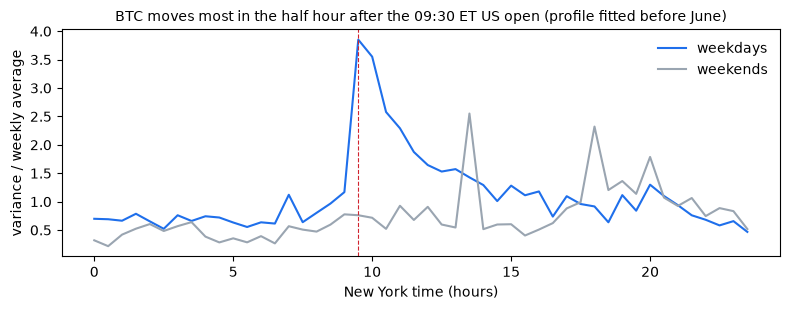

In [14]:
k_train_end = to_minute(mkt, "2026-07-31 17:11:12") - 1
k_apr = to_minute(mkt, "2026-04-01") - 1
prof_final = fit_tod_profile(mkt, 0, k_train_end)[0]
prof_early, prof_late = fit_tod_profile(mkt, 0, k_apr)[0], fit_tod_profile(mkt, k_apr + 1, k_train_end)[0]
card = json.loads((TEAM / "maksim_model_card_profile.json").read_text())
card_prof = np.array(card["time_of_day_profile_weekday_then_weekend_et_half_hours"])
mk_el = pd.read_csv(TEAM / "maksim_time_of_day_profile_early_vs_late.csv")
corr = lambda a, b: np.corrcoef(a, b)[0, 1]
profile_check = pd.DataFrame([
    {"diagnostic": "weekday 09:30-10:00 ET / weekly average", "ours": prof_final[19], "maksim_saved": card_prof[19], "plan": 3.76},
    {"diagnostic": "weekend slots, mean", "ours": prof_final[48:].mean(), "maksim_saved": card_prof[48:].mean(), "plan": 0.71},
    {"diagnostic": "weekday profile corr, Jan-Mar vs Apr-Jul", "ours": corr(prof_early[:48], prof_late[:48]),
     "maksim_saved": corr(mk_el.fit_jan_to_mar[:48], mk_el.fit_apr_to_jul[:48]), "plan": 0.93},
    {"diagnostic": "weekend profile corr, Jan-Mar vs Apr-Jul", "ours": corr(prof_early[48:], prof_late[48:]),
     "maksim_saved": corr(mk_el.fit_jan_to_mar[48:], mk_el.fit_apr_to_jul[48:]), "plan": np.nan},
])
print(profile_check.round(4).to_string(index=False))
print(f"largest difference between our final profile and his saved one: {np.abs(prof_final - card_prof).max():.2e}")

fig, ax = plt.subplots(figsize=(8, 3.2))
hours = np.arange(48) / 2
ax.plot(hours, engines["2026-06-01"]["profile"][:48], label="weekdays", color="#1f6feb")
ax.plot(hours, engines["2026-06-01"]["profile"][48:], label="weekends", color="#9aa5b1")
ax.axvline(9.5, color="#d1242f", lw=0.8, ls="--")
ax.set_xlabel("New York time (hours)")
ax.set_ylabel("variance / weekly average")
ax.set_title("BTC moves most in the half hour after the 09:30 ET US open (profile fitted before June)", fontsize=10)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 6.3 Release variance in each fold (our declared change)

A scheduled release adds variance to any window that contains it. Maksim estimates it from past releases; with only a
handful of releases the estimate is noisy (his README calls it the least stable parameter), so we shrink it toward zero
by m / (m + k_event). For the June and July folds, k_event is chosen on the inner calibration month using only windows
that contain a release; May uses the default.

In [15]:
def choose_k_event(eng, mkt, cal_start, cal_end):
    k_from, k_to = to_minute(mkt, cal_start), to_minute(mkt, cal_end) - 1
    rows = []
    for ke in SETTINGS["k_event_grid"]:
        s = window_scores(eng, mkt, k_from, k_to, ke, release_only=True)
        rows.append({"k_event": ke, "release_windows": int(s.windows.sum()), "mean_deviance": s.deviance.mean()})
    t = pd.DataFrame(rows)
    default = SETTINGS["k_event_default"]
    best = t.mean_deviance.min()
    tie = t.loc[t.k_event == default, "mean_deviance"].iloc[0] <= best * (1 + 1e-12)
    return (default if tie else int(t.loc[t.mean_deviance.idxmin(), "k_event"])), t


k_event_choice = {"2026-05": SETTINGS["k_event_default"]}
for month, f in FOLDS.items():
    if f["inner"] is None:
        continue
    k_event_choice[month], table = choose_k_event(engines[f["inner"]], mkt, f["inner"], f["cutoff"])
    print(f"{month} fold: release shrinkage chosen on {f['inner'][:7]} windows -> k_event = {k_event_choice[month]}")
    print(table.round(3).to_string(index=False))

release_table = pd.DataFrame([{"cutoff": c, "releases_seen": e["releases"], "raw_bps": np.sqrt(e["jump_var_raw"]) * 1e4,
                               "shrunk_bps_k10": np.sqrt(jump_var(e)) * 1e4} for c, e in engines.items()])
print(release_table.round(2).to_string(index=False))

2026-06 fold: release shrinkage chosen on 2026-05 windows -> k_event = 20
 k_event  release_windows  mean_deviance
       0             1236         51.998
       5             1236         47.914
      10             1236         45.760
      20             1236         43.556
2026-07 fold: release shrinkage chosen on 2026-06 windows -> k_event = 0
 k_event  release_windows  mean_deviance
       0             1854         63.051
       5             1854         64.855
      10             1854         66.099
      20             1854         67.704
    cutoff  releases_seen  raw_bps  shrunk_bps_k10
2026-02-01              3     0.00            0.00
2026-03-01              5     0.00            0.00
2026-04-01              8    30.78           20.52
2026-05-01             11    49.18           35.59
2026-06-01             13    45.48           34.19
2026-07-01             16    50.60           39.69


### 6.4 Coefficient stability

If the engine has learned something real, its coefficients should not swing much when one more month of data is added.
The table shows the effect of last-hour volatility (change in log expected move per unit of log variance) for each
product length and cutoff.

In [16]:
stab = []
for c, e in engines.items():
    for t_s in DURATIONS_S:
        sc, glm = e["models"][t_s][0], e["models"][t_s][-1]
        raw = dict(zip(ENGINE_FEATURES, glm.coef_ / sc.scale_))       # per unit of each log feature
        stab.append({"cutoff": c[:7], "length": f"{t_s / 3600:g}h", **raw})
stab = pd.DataFrame(stab)
print("last-hour volatility coefficient (log_var_60m):")
print(stab.pivot(index="length", columns="cutoff", values="log_var_60m").reindex([f"{t / 3600:g}h" for t in DURATIONS_S]).round(3).to_string())
spread = stab.groupby("length")[ENGINE_FEATURES].agg(lambda s: s.max() - s.min())
print("\nrange of each coefficient across the six cutoffs (max - min), by length:")
print(spread.reindex([f"{t / 3600:g}h" for t in DURATIONS_S]).round(3).to_string())

last-hour volatility coefficient (log_var_60m):
cutoff  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07
length                                                      
0.5h      0.280    0.288    0.276    0.263    0.266    0.269
1h        0.260    0.286    0.251    0.236    0.236    0.247
2h        0.274    0.328    0.269    0.253    0.242    0.248
4h        0.154    0.261    0.223    0.194    0.176    0.191
8h        0.146    0.150    0.131    0.121    0.112    0.106
12h       0.187    0.146    0.113    0.114    0.102    0.111
24h       0.065    0.042    0.051    0.063    0.047    0.053

range of each coefficient across the six cutoffs (max - min), by length:
        log_var_60m  log_var_240m  log_var_1440m  log_var_10080m  log_seas_window  log_seas_last60
length                                                                                            
0.5h          0.025         0.025          0.025           0.158            0.087            0.116
1h            0.051         0.02

### 6.5 Walk-forward fair value, February to July (diagnostic)

Each month is priced by the engine fitted only on candles before that month, as in Maksim's walk-forward. We compare our
fair values with his saved ones (they should differ only where a release is in the window, because of the shrinkage),
then ask whether payouts match fair value by product length. The ratios use realised payouts, so they are **diagnostics
only**: nothing in the core model is changed by them.

In [17]:
def boot_ratio(d, num, den, n=SETTINGS["n_boot"], seed=SEED):
    # Ratio of totals with a 90% interval from resampling whole days.
    g = d.groupby("day")[[num, den]].sum()
    idx = np.random.default_rng(seed).integers(0, len(g), size=(n, len(g)))
    b = g[num].to_numpy()[idx].sum(1) / g[den].to_numpy()[idx].sum(1)
    return pd.Series({"orders": len(d), "ratio": g[num].sum() / g[den].sum(), "lo90": np.percentile(b, 5), "hi90": np.percentile(b, 95)})


wf = []
for c in CUTOFFS:
    d = lab[lab.month == c[:7]].copy()
    d["fv"] = fair_value(engines[c], mkt, d)                               # diagnostic fits use k_event = 10
    wf.append(d)
wf = pd.concat(wf).merge(pd.read_csv(TEAM / "maksim_walk_forward.csv")[["row_id", "fair_value_USDC"]], left_on="row", right_on="row_id")
fv_match = wf.groupby(["month", "release_in_window"]).apply(lambda g: pd.Series({
    "orders": len(g), "ours_over_maksim": g.fv.sum() / g.fair_value_USDC.sum()}), include_groups=False).unstack()
print("our fair value / Maksim's saved fair value (0 = no release in window, 1 = release in window):")
print(fv_match.round(4).to_string())

pf = pd.concat({f"{t / 3600:g}h": boot_ratio(wf[wf.productType == t], "realizedProfit_USDC", "fv") for t in DURATIONS_S}, axis=1).T
pf.loc["all"] = boot_ratio(wf, "realizedProfit_USDC", "fv")
print("\npayout / fair value, Feb-Jul walk-forward, with 90% day-bootstrap intervals (diagnostic only):")
print(pf.round(3).to_string())

our fair value / Maksim's saved fair value (0 = no release in window, 1 = release in window):
                   orders        ours_over_maksim        
release_in_window       0      1                0       1
month                                                    
2026-02             210.0    1.0              1.0  1.0000
2026-03             251.0   15.0              1.0  1.0000
2026-04             820.0   47.0              1.0  0.9660
2026-05             937.0   28.0              1.0  0.9324
2026-06            2187.0   83.0              1.0  0.9545
2026-07            2462.0  109.0              1.0  0.9504

payout / fair value, Feb-Jul walk-forward, with 90% day-bootstrap intervals (diagnostic only):
      orders  ratio   lo90   hi90
0.5h  3090.0  0.908  0.768  1.072
1h     531.0  1.120  0.951  1.311
2h    1091.0  0.989  0.822  1.157
4h    1240.0  1.000  0.840  1.176
8h     991.0  0.952  0.782  1.155
12h     46.0  1.061  0.843  1.419
24h    161.0  0.446  0.219  0.817
all   7150.0  0.

## 7. Reference price: our estimate of JV's current price

The reference does two jobs: it sets the overall price level (so our prices are calibrated to what JV charges, not to
our own idea of the right margin) and the per-order limits (each quote stays within 0.8-1.2 times it). It never uses the
base price, the paid price or the markup as an input. Its target is JV's charged volatility *relative to* the last day's
realised volatility. The plan's evidence for this is that JV's raw charged level swings much more from month to month
than its level relative to realised volatility; the first table below recomputes that comparison from the data.

In [18]:
REF_X = ["rsi_15m", "pctb_15m", "log_rv60_1d", "log_rv_1d", "log_rv_7d"]


def add_ref_columns(d):
    d = d.copy()
    d["log_rv60_1d"] = np.log(d.rv_60 / d.rv_1d)
    d["log_rv_1d"], d["log_rv_7d"] = np.log(d.rv_1d), np.log(d.rv_7d)
    return d


train, blind = add_ref_columns(train), add_ref_columns(blind)
lab = train[train.realizedProfit_USDC.notna()].copy()
assert (lab.premiumAmount_USDC > 0).all(), "a zero premium would break the ratios"

level_by_month = lab.groupby("month").apply(lambda g: pd.Series({
    "charged_vol": g.premiumAmount_USDC.sum() / g.scale.sum(),
    "charged_over_rv1d": g.premiumAmount_USDC.sum() / (g.scale * g.rv_1d).sum()}), include_groups=False)
level_by_month["raw_change"] = level_by_month.charged_vol.pct_change()
level_by_month["relative_change"] = level_by_month.charged_over_rv1d.pct_change()
print("JV's charged level by month: raw vs relative to pre-trade 1-day realised vol")
print(level_by_month.round(3).to_string())


def eligible(cutoff):
    # Labels created AND settled before the cutoff: the only training rows a fit may use.
    c = pd.Timestamp(cutoff)
    return lab[(lab.createdAt < c) & (lab.closedAt < c)]


def ref_design(d, dur_cols):
    X = pd.DataFrame({f"dur_{t}": (d.productType == t).astype(float).to_numpy() for t in dur_cols})
    for c in REF_X:
        X[c] = d[c].to_numpy()
    return X.to_numpy()


def reference_raw(ref, d):
    out = d.scale.to_numpy() * d.productType.map(ref["levels"]).to_numpy() * d.rv_1d.to_numpy()   # b = 1
    if ref["ridge"] is not None:
        seen = d.productType.isin(ref["dur_cols"]).to_numpy()
        if seen.any():
            ratio = np.exp(ref["ridge"].predict(ref_design(d[seen], ref["dur_cols"])))
            out[seen] = d.scale.to_numpy()[seen] * ratio * d.rv_1d.to_numpy()[seen]
    return out


def fit_reference(fit, kind, value):
    pooled = fit.premiumAmount_USDC.sum() / (fit.scale * fit.rv_1d).sum()
    g = fit.assign(den=fit.scale * fit.rv_1d).groupby("productType").agg(A=("premiumAmount_USDC", "sum"), den=("den", "sum"), n=("row", "size"))
    w = g.n / (g.n + (value if kind == "dur" else SETTINGS["k_ref_default"]))
    seen = w * g.A / g.den + (1 - w) * pooled
    levels = {t: float(np.interp(np.log(t), np.log(seen.index.to_numpy(float)), seen.to_numpy())) for t in DURATIONS_S}
    ref = {"kind": kind, "value": value, "levels": levels, "dur_cols": list(seen.index), "ridge": None}
    if kind == "ridge":
        weights = (fit.notional / fit.notional.mean()).to_numpy()
        ref["ridge"] = make_pipeline(StandardScaler(), Ridge(alpha=value)).fit(
            ref_design(fit, ref["dur_cols"]), np.log((fit.premiumAmount_USDC / fit.scale) / fit.rv_1d), ridge__sample_weight=weights)
    last = sorted(fit.month.unique())[-SETTINGS["level_months"]:]
    sub = fit[fit.month.isin(last)]
    ref["level_factor"] = sub.premiumAmount_USDC.sum() / reference_raw(ref, sub).sum()
    ref["level_months"] = last
    return ref


def reference_price(ref, d):
    return reference_raw(ref, d) * ref["level_factor"]


def ref_errors(p_ref, d):
    a, w = d.premiumAmount_USDC.to_numpy(), d.notional.to_numpy()
    return {"bias": (p_ref - a).sum() / a.sum(), "weighted_abs_error": (w * np.abs(p_ref / a - 1)).sum() / w.sum()}

JV's charged level by month: raw vs relative to pre-trade 1-day realised vol


         charged_vol  charged_over_rv1d  raw_change  relative_change
month                                                               
2026-02        0.663              1.153         NaN              NaN
2026-03        0.852              1.371       0.285            0.189
2026-04        0.531              1.300      -0.377           -0.052
2026-05        0.415              1.244      -0.219           -0.043
2026-06        0.570              1.184       0.375           -0.049
2026-07        0.488              1.329      -0.144            0.122


In [19]:
def choose_reference(inner_fit, cal):
    rows = []
    for kind, values in [("dur", SETTINGS["k_ref_grid"]), ("ridge", SETTINGS["ridge_alphas"])]:
        for v in values:
            rows.append({"kind": kind, "value": v, **ref_errors(reference_price(fit_reference(inner_fit, kind, v), cal), cal)})
    t = pd.DataFrame(rows)
    dur, ridge = t[t.kind == "dur"], t[t.kind == "ridge"]
    best_dur = dur.weighted_abs_error.min()
    pick = dur[dur.weighted_abs_error <= best_dur * (1 + 1e-12)]
    chosen = ("dur", SETTINGS["k_ref_default"]) if SETTINGS["k_ref_default"] in pick.value.to_numpy() else ("dur", int(pick.value.iloc[0]))
    if ridge.weighted_abs_error.min() <= best_dur - SETTINGS["ridge_margin"]:
        chosen = ("ridge", ridge.loc[ridge.weighted_abs_error.idxmin(), "value"])
    return chosen, t


ref_choice, ref_tables = {"2026-05": ("dur", SETTINGS["k_ref_default"])}, {}
for month, f in FOLDS.items():
    if f["inner"] is None:
        continue
    cal = lab[(lab.month == f["inner"][:7]) & (lab.closedAt < pd.Timestamp(f["cutoff"]))]
    ref_choice[month], ref_tables[month] = choose_reference(eligible(f["inner"]), cal)
    print(f"{month} fold: reference chosen on {f['inner'][:7]} -> {ref_choice[month]}")
    print(ref_tables[month].round(4).to_string(index=False))

refs, audit = {}, []
for month, f in FOLDS.items():
    refs[month] = fit_reference(eligible(f["cutoff"]), *ref_choice[month])
    test = lab[lab.month == month]
    err = ref_errors(reference_price(refs[month], test), test)
    passes = abs(err["bias"]) <= SETTINGS["audit_bias"] and err["weighted_abs_error"] <= SETTINGS["audit_wae"]
    audit.append({"held_out_month": month, "spec": f"{ref_choice[month][0]} {ref_choice[month][1]}",
                  "level_months": ", ".join(refs[month]["level_months"]), "level_factor": refs[month]["level_factor"],
                  **err, "passes": passes if month != "2026-07" else "retrospective"})
audit = pd.DataFrame(audit)
print(audit.round(4).to_string(index=False))
ref_audit_pass = bool(audit.loc[audit.held_out_month.isin(["2026-05", "2026-06"]), "passes"].all())
print("reference audit (May and June):", "PASS" if ref_audit_pass else "FAIL")

2026-06 fold: reference chosen on 2026-05 -> ('dur', 25)
 kind  value    bias  weighted_abs_error
  dur     25 -0.0240              0.2095
  dur    100 -0.0155              0.2138
  dur    400 -0.0012              0.2236
ridge    100  0.1509              0.2259
ridge     10  0.1505              0.2225
ridge      1  0.1498              0.2219


2026-07 fold: reference chosen on 2026-06 -> ('ridge', np.int64(100))
 kind  value    bias  weighted_abs_error
  dur     25  0.0712              0.2547
  dur    100  0.0721              0.2567
  dur    400  0.0723              0.2626
ridge    100 -0.0876              0.2064
ridge     10 -0.0944              0.2126
ridge      1 -0.0951              0.2135
held_out_month      spec              level_months  level_factor    bias  weighted_abs_error        passes
       2026-05   dur 100 2026-02, 2026-03, 2026-04        0.9760 -0.0159              0.2139          True
       2026-06    dur 25 2026-03, 2026-04, 2026-05        1.0064  0.0710              0.2546          True
       2026-07 ridge 100 2026-04, 2026-05, 2026-06        1.0248 -0.1241              0.1747 retrospective
reference audit (May and June): PASS


## 8. The price step: JV's level x fair-value shape

`shape_raw = FV / P_ref` says how much riskier (or safer) an order is than the reference assumes. We divide by n so that,
on the fold's own training orders, the quotes add up to the reference total; then clip to 0.8-1.2 and apply the cost
floor `P >= FV` (the Lerner-rule lower bound: price at least marginal cost). n is solved once per fold by bisection and
then frozen, so later months' totals can drift; we report that drift instead of hiding it. If even the largest n
cannot bring the total down to the reference total, the cost floor alone is above it: the plan says to stop and report,
so that candidate gets no quotes (status INFEASIBLE). F0 scales fair value to
the training premium total with no reference, and C3 is the payout-fitted duration ladder from JV-03, as comparators.

In [20]:
def quote_f1(p_ref, fv, n, lam=1.0, theta=0.0, floor=True):
    shape = 1 + lam * (np.clip(fv / p_ref / n, *SETTINGS["band"]) - 1)
    p = p_ref * shape * (1 + theta)
    return np.maximum(p, fv) if floor else p


def solve_n(p_ref, fv, lam):
    # Geometric bisection: the quoted total falls as n rises. Returns (n, status).
    lo, hi = SETTINGS["n_bracket"]
    target = p_ref.sum()
    total = lambda n: quote_f1(p_ref, fv, n, lam).sum()
    if total(hi) > target:                     # the plan's stop rule: report, do not force a solution
        return np.nan, f"INFEASIBLE: at n = {hi:g} the cost floor alone is {total(hi) / target - 1:+.2%} over the reference total"
    assert total(lo) > target, "bracket does not contain the solution"
    for _ in range(300):
        mid = np.sqrt(lo * hi)
        lo, hi = (mid, hi) if total(mid) > target else (lo, mid)
        if abs(total(mid) / target - 1) <= SETTINGS["n_tol"]:
            return mid, "ok"
    raise ValueError("bisection did not reach the tolerance")


def fit_c3(fit):
    # JV-03 ladder: needed (break-even) vol per length, shrunk toward the pooled level, plus a 7.5% margin.
    v_all = fit.realizedProfit_USDC.sum() / fit.scale.sum()
    g = fit.groupby("productType").agg(pay=("realizedProfit_USDC", "sum"), sc=("scale", "sum"), n=("row", "size"))
    w = g.n / (g.n + SETTINGS["c3_k"])
    ladder = (w * g.pay / g.sc + (1 - w) * v_all).to_dict()
    return {t: ladder.get(t, v_all) * (1 + SETTINGS["c3_theta"]) for t in DURATIONS_S}


folds, norm_rows, clip_rows = {}, [], []
for month, f in FOLDS.items():
    eng, ref, ke = engines[f["cutoff"]], refs[month], k_event_choice[month]
    fit, test = eligible(f["cutoff"]).copy(), lab[lab.month == month].copy()
    for d in (fit, test):
        d["fv"], d["p_ref"] = fair_value(eng, mkt, d, ke), reference_price(ref, d)
    solved = {name: solve_n(fit.p_ref.to_numpy(), fit.fv.to_numpy(), lam) for name, lam in SETTINGS["lambdas"].items()}
    n, n_status = {k: v[0] for k, v in solved.items()}, {k: v[1] for k, v in solved.items()}
    assert n_status["F1"] == "ok", "F1 itself cannot be normalised: stop"
    c_f0, c3 = fit.premiumAmount_USDC.sum() / fit.fv.sum(), fit_c3(fit)
    for d in (fit, test):
        d["shape_raw_n"] = d.fv / d.p_ref / n["F1"]
        for name, lam in SETTINGS["lambdas"].items():
            d[f"q_{name}"] = quote_f1(d.p_ref.to_numpy(), d.fv.to_numpy(), n[name], lam)
        d["q_F1nf"] = quote_f1(d.p_ref.to_numpy(), d.fv.to_numpy(), n["F1"], 1.0, floor=False)
        d["q_R0"], d["q_F0"] = d.p_ref, d.fv * c_f0
        d["q_C3"] = d.scale * d.productType.map(c3)
    folds[month] = {"fit": fit, "test": test, "n": n, "n_status": n_status, "c_f0": c_f0, "c3": c3, "k_event": ke, "ref": ref}
    for name in SETTINGS["lambdas"]:
        row = {"month": month, "model": name, "status": n_status[name], "n": n[name], "fit_rows": len(fit),
               "fit_total_error": np.nan, "held_out_quotes_over_Pref": np.nan, "held_out_quotes_over_A": np.nan, "floor_binds": np.nan}
        if n_status[name] == "ok":
            band = test.p_ref * (1 + SETTINGS["lambdas"][name] * (np.clip(test.fv / test.p_ref / n[name], *SETTINGS["band"]) - 1))
            row.update({"fit_total_error": fit[f"q_{name}"].sum() / fit.p_ref.sum() - 1,
                        "held_out_quotes_over_Pref": test[f"q_{name}"].sum() / test.p_ref.sum(),
                        "held_out_quotes_over_A": test[f"q_{name}"].sum() / test.premiumAmount_USDC.sum(),
                        "floor_binds": (test.fv > band).mean()})
        norm_rows.append(row)
    lo, hi = SETTINGS["band"]
    for t_s, g in test.groupby("productType"):
        clip_rows.append({"month": month, "length": f"{t_s / 3600:g}h", "orders": len(g),
                          "lower": (g.shape_raw_n < lo).mean(), "upper": (g.shape_raw_n > hi).mean(),
                          "upper_notional": g.notional[g.shape_raw_n > hi].sum() / g.notional.sum()})
    clip_rows.append({"month": month, "length": "all", "orders": len(test), "lower": (test.shape_raw_n < lo).mean(),
                      "upper": (test.shape_raw_n > hi).mean(), "upper_notional": test.notional[test.shape_raw_n > hi].sum() / test.notional.sum()})

norm_table = pd.DataFrame(norm_rows)
ok = norm_table.status == "ok"
assert (norm_table.fit_total_error[ok].abs() <= SETTINGS["n_tol"]).all(), "normalisation missed its tolerance"
print(norm_table.drop(columns="status").to_string(index=False, float_format=lambda v: f"{v:.4g}"))
for _, r in norm_table[~ok].iterrows():
    print(f"{r.month} {r.model}: {r.status}")
clip_table = pd.DataFrame(clip_rows)
clip_table["clipped"] = clip_table.lower + clip_table.upper
print(clip_table.round(3).to_string(index=False))
flag_upper = clip_table[(clip_table.length == "all") & (clip_table.upper > SETTINGS["clip_upper_max"])]
flag_length = clip_table[(clip_table.length != "all") & (clip_table.length != "0.5h") & (clip_table.clipped > SETTINGS["clip_length_max"])]
clip_checkpoint = "PASS" if flag_upper.empty and flag_length.empty else "STOP: see flagged rows"
print("clipping checkpoint:", clip_checkpoint)
if not (flag_upper.empty and flag_length.empty):
    print(pd.concat([flag_upper, flag_length]).round(3).to_string(index=False))

  month model      n  fit_rows  fit_total_error  held_out_quotes_over_Pref  held_out_quotes_over_A  floor_binds
2026-05    F1 0.9107      1343       -8.054e-09                      1.062                   1.045       0.1699
2026-05   F1h    NaN      1343              NaN                        NaN                     NaN          NaN
2026-06    F1 0.9555      2306        2.065e-09                     0.9757                   1.045       0.1476
2026-06   F1h    NaN      2306              NaN                        NaN                     NaN          NaN
2026-07    F1  0.981      4576        1.554e-09                      1.136                   0.995       0.1879
2026-07   F1h    NaN      4576              NaN                        NaN                     NaN          NaN
2026-05 F1h: INFEASIBLE: at n = 100 the cost floor alone is +0.15% over the reference total
2026-06 F1h: INFEASIBLE: at n = 100 the cost floor alone is +2.61% over the reference total
2026-07 F1h: INFEASIBLE: at n = 

## 9. Phase 3 — the team scorecard

Every model is scored on the same orders: all resolved orders created in May, June and July, each priced by its fold's
models (fitted only on earlier data). May + June decide; July is reported as a retrospective check and never changes a
choice. The order follows the plan: first what F1h and the band do, then the placebo power check (before any
candidate's real score is printed), then the scores, the selection rule, robustness and the payout attribution.
Everything is saved under `aman/team_scorecard/`.

In [21]:
from sklearn.isotonic import IsotonicRegression

OUT3 = AMAN / "team_scorecard"
OUT3.mkdir(exist_ok=True)

SCENARIOS = {"no response": None}
SCENARIOS.update({f"smooth e={e:g}": ("smooth", e) for e in (0.5, 1.0, 2.0)})
SCENARIOS.update({f"conservative e={e:g}": ("conservative", e) for e in (1.0, 2.0, 4.0, 8.0, 20.0)})
SCENARIOS.update({f"keep if r<={v:.2f}": ("threshold", v) for v in (1.0, 1.10, 1.20, 1.25)})
CENTRAL = "conservative e=2"
assert SCENARIOS[CENTRAL] == SETTINGS["central"]

MODELS = ["C0", "R0", "F0", "F1", "F1nf", "C3", "M", "S"]          # full panels; C1 has its own base-rows panel
ROLE = {"C0": "benchmark (JV's price)", "R0": "default / fallback", "F0": "candidate", "F1": "candidate",
        "F1h": "infeasible", "F1nf": "diagnostic", "C3": "comparator", "M": "comparator (Maksim)",
        "S": "comparator (Subham)", "C1": "comparator (base rows)", "J": "N/A (Jay)"}


def demand_weight(r, scen):
    # Volume factor for an order priced at r times today's price (an assumption, not an estimate).
    if scen is None:
        return np.ones_like(r)
    kind, v = scen
    if kind == "smooth":
        return np.minimum(r ** -v, 3.0)
    if kind == "conservative":
        return np.minimum(r ** -v, 1.0)
    return (r <= v + 1e-12).astype(float)                              # threshold: keep only if P <= v x A


mk_wf = pd.read_csv(TEAM / "maksim_walk_forward.csv")[["row_id", "model_premium_USDC"]].rename(columns={"model_premium_USDC": "q_M"})
sb = pd.read_csv(TEAM / "subham_backtest_selected.csv")[["row_id", "model_premium_USDC"]].rename(columns={"model_premium_USDC": "q_S"})


def month_panel(month):
    t = folds[month]["test"].merge(mk_wf, left_on="row", right_on="row_id", how="left").drop(columns="row_id")
    t = t.merge(sb, left_on="row", right_on="row_id", how="left").drop(columns="row_id")
    t["q_C0"], t["q_C1"] = t.premiumAmount_USDC, t.base_usd
    assert t[[f"q_{m}" for m in MODELS]].notna().all().all() and (t[[f"q_{m}" for m in MODELS]] > 0).all().all()
    return t.reset_index(drop=True)


panels = {m: month_panel(m) for m in FOLDS}
print({m: len(t) for m, t in panels.items()}, "orders per month; every model has a positive quote for every order")

{'2026-05': 965, '2026-06': 2270, '2026-07': 2571} orders per month; every model has a positive quote for every order


### 9.1 F1h, the band and the cost floor

F1h failed its declared training-total calibration in Phase 2, so it gets no quotes and is reported as *infeasible*.
The first table shows, by fold, how far the cost floor alone pushes the total above the reference total and how often fair
value is above the reference price. The second shows how often F1's band binds (upper and lower, measured on
shape_raw / n) and how many orders the cost floor raises, by month and product length.

In [22]:
f1h_rows = []
for month, f in folds.items():
    fit, test = f["fit"], f["test"]
    floor_only = np.maximum(0.9 * fit.p_ref, fit.fv).sum() / fit.p_ref.sum() - 1     # lambda = 0.5 at the largest n
    f1h_rows.append({"fold": month, "status": "infeasible" if f["n_status"]["F1h"] != "ok" else "ok",
                     "floor_alone_over_reference_total": floor_only,
                     "share_FV_above_Pref_fit_rows": (fit.fv > fit.p_ref).mean(),
                     "share_FV_above_Pref_test_month": (test.fv > test.p_ref).mean()})
f1h_table = pd.DataFrame(f1h_rows)
print(f1h_table.to_string(index=False, float_format=lambda v: f"{v:.2%}"))
f1h_table.to_csv(OUT3 / "f1h_infeasibility.csv", index=False)

band_rows = []
lo_b, hi_b = SETTINGS["band"]
for month, t in panels.items():
    band = t.p_ref * np.clip(t.fv / t.p_ref / folds[month]["n"]["F1"], lo_b, hi_b)
    t["floor_raised"] = t.fv > band
    for length, g in [*[(f"{d / 3600:g}h", t[t.productType == d]) for d in DURATIONS_S], ("all", t)]:
        if len(g) == 0:
            continue
        band_rows.append({"month": month, "length": length, "orders": len(g),
                          "upper_bound": (g.shape_raw_n > hi_b).mean(), "lower_bound": (g.shape_raw_n < lo_b).mean(),
                          "clipped": ((g.shape_raw_n > hi_b) | (g.shape_raw_n < lo_b)).mean(),
                          "floor_raised_orders": int(g.floor_raised.sum()), "floor_raised_share": g.floor_raised.mean()})
band_table = pd.DataFrame(band_rows)
band_table.to_csv(OUT3 / "clipping_and_floor.csv", index=False)
print(band_table.round(3).to_string(index=False))

   fold     status  floor_alone_over_reference_total  share_FV_above_Pref_fit_rows  share_FV_above_Pref_test_month
2026-05 infeasible                             0.15%                        25.02%                          37.82%
2026-06 infeasible                             2.61%                        25.85%                          25.73%
2026-07 infeasible                             4.97%                        23.62%                          28.78%
  month length  orders  upper_bound  lower_bound  clipped  floor_raised_orders  floor_raised_share
2026-05   0.5h     349        0.189        0.352    0.542                   21               0.060
2026-05     2h     299        0.278        0.324    0.602                   51               0.171
2026-05     4h     183        0.519        0.219    0.738                   80               0.437
2026-05     8h     113        0.150        0.257    0.407                    8               0.071
2026-05    24h      21        0.286        0.

### 9.2 Placebo power check (run before any candidate's real score)

Profit in a month is driven by a few large payouts, so we first measure how big a profit gain pure chance can produce.
Each placebo keeps F1's exact band, floor and n but shuffles its shape at random among orders of the same product length
and month, so it charges the same *kind* of prices with no information about which order is riskier (a permutation test).
The spread of placebo gains over R0 in the central scenario is the noise floor.

In [23]:
def central_profit(P, A, pay):
    return np.sum(demand_weight(P / A, SCENARIOS[CENTRAL]) * (P - pay))


def f1_shape(t):
    n = np.array([folds[m]["n"]["F1"] for m in t.month])
    return np.clip(t.fv.to_numpy() / t.p_ref.to_numpy() / n, *SETTINGS["band"])


def shuffle_within(values, groups, rng):
    out = values.copy()
    for g in np.unique(groups):
        idx = np.flatnonzero(groups == g)
        out[idx] = values[rng.permutation(idx)]
    return out


rng_placebo = np.random.default_rng(SEED)
mj = pd.concat([panels["2026-05"], panels["2026-06"]], ignore_index=True)
A_mj, pay_mj = mj.q_C0.to_numpy(), mj.realizedProfit_USDC.to_numpy()
base_r0 = central_profit(mj.q_R0.to_numpy(), A_mj, pay_mj)
shape_mj, groups_mj = f1_shape(mj), (mj.month + "_" + mj.productType.astype(str)).to_numpy()
placebo_gain = np.array([central_profit(np.maximum(mj.p_ref.to_numpy() * shuffle_within(shape_mj, groups_mj, rng_placebo),
                                                   mj.fv.to_numpy()), A_mj, pay_mj) - base_r0
                         for _ in range(SETTINGS["n_placebo"])])
p5, p95 = np.percentile(placebo_gain, [5, 95])
delta = SETTINGS["delta_share"] * A_mj.sum()
half_width = (p95 - p5) / 2
underpowered = half_width > delta
pd.Series(placebo_gain, name="placebo_gain_vs_R0").to_csv(OUT3 / "placebo_gains.csv", index=False)
print(f"placebo gains over R0 (May + June, {CENTRAL}): 90% range {p5:,.0f} to {p95:,.0f} USDC; "
      f"minimum detectable gain {p95:,.0f}; half-width {half_width:,.0f} vs delta {delta:,.0f} (2% of May + June premium)")
print("profit test (c):", "UNDERPOWERED -> uses 'upper 90% bound of (candidate - R0) >= 0' as declared" if underpowered
      else "powered -> uses 'lower 90% bound of (candidate - R0) > -delta'")

placebo gains over R0 (May + June, conservative e=2): 90% range 9,580 to 11,174 USDC; minimum detectable gain 11,174; half-width 797 vs delta 2,541 (2% of May + June premium)
profit test (c): powered -> uses 'lower 90% bound of (candidate - R0) > -delta'


### 9.3 Scores under every demand scenario, with each model's same-total flat change (C2)

For each model and month: profit, revenue, loss ratio, today's premium kept, order volume, worst creation day and daily
P&L spread, under all twelve demand scenarios. Next to every model sits its C2: JV's actual prices scaled up or down
uniformly so the total quote equals the model's. If a model beats its C2, the gain comes from *where* it charges, not
from charging more or less overall.

In [24]:
def scenario_metrics(P, A, pay, day, row, scen):
    w = demand_weight(P / A, scen)
    pnl = w * (P - pay)
    daily = pd.Series(pnl).groupby(day).sum()
    n_top = int(np.ceil(0.01 * len(pay)))
    top = np.lexsort((row, -pay))[:n_top]                              # largest payouts first, ties by row
    total = pnl.sum()
    revenue = (w * P).sum()
    return {"profit": total, "revenue": revenue, "payout": (w * pay).sum(), "loss_ratio": (w * pay).sum() / revenue if revenue > 0 else np.nan,
            "premium_kept": (w * A).sum() / A.sum(), "volume": w.mean(), "worst_day": daily.min(), "daily_sd": daily.std(ddof=1),
            "top1pct_payout_contribution": pnl[top].sum(),
            "top1pct_share_of_profit": pnl[top].sum() / total if abs(total) > 0.01 * (w * P).sum() else np.nan}


def score_panel(t, models):
    A, pay, day, row = t.q_C0.to_numpy(), t.realizedProfit_USDC.to_numpy(), t.day.to_numpy(), t.row.to_numpy()
    rows = []
    for m in models:
        P = t[f"q_{m}"].to_numpy()
        for version, Q in [("model", P), ("C2", A * P.sum() / A.sum())]:
            for sname, scen in SCENARIOS.items():
                rows.append({"model": m, "version": version, "scenario": sname, "quoted_over_C0": Q.sum() / A.sum(),
                             "quoted_over_Pref": Q.sum() / t.p_ref.sum(), **scenario_metrics(Q, A, pay, day, row, scen)})
    return pd.DataFrame(rows)


score = pd.concat([score_panel(t, MODELS).assign(month=m) for m, t in panels.items()], ignore_index=True)
base_panels = {m: t[t.q_C1.notna()].reset_index(drop=True) for m, t in panels.items()}
score_c1 = pd.concat([score_panel(t, ["C0", "C1"]).assign(month=m, panel="base rows") for m, t in base_panels.items()], ignore_index=True)
score.to_csv(OUT3 / "scores_by_month_and_scenario.csv", index=False)
score_c1.to_csv(OUT3 / "scores_C1_base_rows.csv", index=False)
print(f"{len(score)} model x version x scenario x month rows saved (+ {len(score_c1)} on the base-rows panel for C1)")

624 model x version x scenario x month rows saved (+ 156 on the base-rows panel for C1)


### 9.4 Uncertainty, ranking and calibration

**Paired day bootstrap.** Days are resampled within each month (2,000 draws, fixed seed), keeping each month's number of
days, and May + June are summed. The same draws are used for every model and scenario, and each draw recomputes the C2
factors and the Gini tie groups, so the intervals compare like with like. They are conditional on the models and the
demand scenarios; they are not proof of commercial demand.

**Gini** (Frees, Meyers & Cummings, 2011): orders sorted by quote / JV's price, tied ratios grouped, x = cumulative share
of JV's premium, y = cumulative share of payouts. Positive means the orders the model marks up relative to JV really do
pay out more. **CORP** (Gneiting & Resin, 2023) splits the Poisson score of quote / scale against payout / scale into
calibration error (MCB), ranking power (DSC) and outcome noise (UNC), using an isotonic recalibration. A high Gini from a
badly calibrated model does not win (Wüthrich, 2023).

In [25]:
def day_counts(n_days, n_boot, rng):
    idx = rng.integers(0, n_days, size=(n_boot, n_days))
    counts = np.zeros((n_boot, n_days))
    np.add.at(counts, (np.repeat(np.arange(n_boot), n_days), idx.ravel()), 1.0)
    return counts


rng_boot = np.random.default_rng(SEED)
BOOT = {}
for month, t in panels.items():
    days = np.sort(t.day.unique())
    BOOT[month] = {"pos": np.searchsorted(days, t.day.to_numpy()), "n_days": len(days),
                   "counts": day_counts(len(days), SETTINGS["n_boot"], rng_boot)}


def day_sums(values, b):
    return np.bincount(b["pos"], weights=values, minlength=b["n_days"])


def profit_draws(t, P, scen, b):
    A, pay = t.q_C0.to_numpy(), t.realizedProfit_USDC.to_numpy()
    return b["counts"] @ day_sums(demand_weight(P / A, scen) * (P - pay), b)


def c2_draws(t, P, scen, b):
    # The flat change is recomputed inside every draw: factor = sum(P) / sum(A) on the resampled days.
    tot = [b["counts"] @ day_sums(v, b) for v in (t.q_C0.to_numpy(), P, t.realizedProfit_USDC.to_numpy())]
    f = tot[1] / tot[0]
    return demand_weight(f, scen) * (f * tot[0] - tot[2])


draws = {}
for month, t in panels.items():
    for m in MODELS:
        P = t[f"q_{m}"].to_numpy()
        for sname, scen in SCENARIOS.items():
            draws[(month, m, sname)] = profit_draws(t, P, scen, BOOT[month])
            draws[(month, m + "_C2", sname)] = c2_draws(t, P, scen, BOOT[month])


def interval(x):
    return np.percentile(x, 5), np.percentile(x, 95)


def mj_draws(key_model, sname):
    return draws[("2026-05", key_model, sname)] + draws[("2026-06", key_model, sname)]


PROFIT = score.set_index(["model", "version", "scenario", "month"]).profit


def point_profit(model, version, sname, months):
    return sum(PROFIT[(model, version, sname, mm)] for mm in months)


diff_rows = []
for m in MODELS:
    for sname in SCENARIOS:
        for ref in ["C0", m + "_C2", "R0"]:
            ref_model, ref_version = (m, "C2") if ref.endswith("_C2") else (ref, "model")
            for period, d in [("May+June", mj_draws(m, sname) - mj_draws(ref, sname)),
                              ("July (retrospective)", draws[("2026-07", m, sname)] - draws[("2026-07", ref, sname)])]:
                months = ["2026-05", "2026-06"] if period == "May+June" else ["2026-07"]
                point = point_profit(m, "model", sname, months) - point_profit(ref_model, ref_version, sname, months)
                lo, hi = interval(d)
                diff_rows.append({"model": m, "scenario": sname, "versus": "own C2" if ref.endswith("_C2") else ref,
                                  "period": period, "difference": point, "lo90": lo, "hi90": hi})
diffs = pd.DataFrame(diff_rows)
diffs.to_csv(OUT3 / "profit_differences_bootstrap.csv", index=False)
print(f"{len(diffs)} paired-bootstrap profit differences saved")

624 paired-bootstrap profit differences saved


In [26]:
def tie_groups(ratio):
    order = np.argsort(ratio, kind="stable")
    r = ratio[order]
    new = np.r_[True, np.abs(np.diff(r)) > SETTINGS["gini_tie_tol"] * np.abs(r[1:])]
    return order, np.cumsum(new) - 1


def gini_from_groups(ga, gy):
    # Signed area: 2 x integral of (x - y) dx along the ordered Lorenz curve, with (0, 0) and (1, 1) included.
    x, y = np.cumsum(ga, axis=0) / ga.sum(axis=0), np.cumsum(gy, axis=0) / gy.sum(axis=0)
    x0, y0 = np.concatenate([np.zeros_like(x[:1]), x[:-1]]), np.concatenate([np.zeros_like(y[:1]), y[:-1]])
    return ((x - x0) * ((x + x0) - (y + y0))).sum(axis=0)


def gini(ratio, ref, pay):
    order, gid = tie_groups(ratio)
    return gini_from_groups(np.bincount(gid, weights=ref[order]), np.bincount(gid, weights=pay[order]))


def gini_draws(ratio, ref, pay, b):
    order, gid = tie_groups(ratio)
    ma, my = np.zeros((gid.max() + 1, b["n_days"])), np.zeros((gid.max() + 1, b["n_days"]))
    np.add.at(ma, (gid, b["pos"][order]), ref[order])
    np.add.at(my, (gid, b["pos"][order]), pay[order])
    return gini_from_groups(ma @ b["counts"].T, my @ b["counts"].T)


gini_rows, gini_summary = [], {}
for m in MODELS + ["FV"]:
    per_month, per_draw, weights = {}, {}, {}
    for month, t in panels.items():
        A, pay = t.q_C0.to_numpy(), t.realizedProfit_USDC.to_numpy()
        P = t.fv.to_numpy() if m == "FV" else t[f"q_{m}"].to_numpy()
        per_month[month] = gini(P / A, A, pay)
        per_draw[month] = gini_draws(P / A, A, pay, BOOT[month])
        weights[month] = BOOT[month]["counts"] @ day_sums(A, BOOT[month])
        tb = base_panels[month]
        Pb = tb.fv.to_numpy() if m == "FV" else tb[f"q_{m}"].to_numpy()
        gini_rows.append({"model": m, "month": month, "gini_vs_JV_price": per_month[month],
                          "lo90": interval(per_draw[month])[0], "hi90": interval(per_draw[month])[1],
                          "gini_vs_base_on_base_rows": gini(Pb / tb.base_usd.to_numpy(), tb.base_usd.to_numpy(), tb.realizedProfit_USDC.to_numpy())})
    wA = {mm: panels[mm].q_C0.sum() for mm in ["2026-05", "2026-06"]}
    point = (wA["2026-05"] * per_month["2026-05"] + wA["2026-06"] * per_month["2026-06"]) / sum(wA.values())
    boot = (weights["2026-05"] * per_draw["2026-05"] + weights["2026-06"] * per_draw["2026-06"]) / (weights["2026-05"] + weights["2026-06"])
    gini_summary[m] = {"point": point, "lo90": interval(boot)[0], "hi90": interval(boot)[1]}
gini_table = pd.DataFrame(gini_rows)
gini_table.to_csv(OUT3 / "gini_by_month.csv", index=False)
print("Gini of quote / JV price (May+June summary, 90% interval); 'FV' = raw fair value before the band and floor:")
print(pd.DataFrame(gini_summary).T.round(4).to_string())


def mean_dev(y, p, w):
    return np.sum(w * poisson_deviance(y, np.maximum(p, 1e-12))) / w.sum()


def corp(quote, pay, scale):
    x, y, w = quote / scale, pay / scale, scale
    rc = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x, y, sample_weight=w).predict(x)
    unc = mean_dev(y, np.full_like(y, np.sum(w * y) / w.sum()), w)
    s_x, s_rc = mean_dev(y, x, w), mean_dev(y, rc, w)
    return {"score": s_x, "MCB": s_x - s_rc, "DSC": unc - s_rc, "UNC": unc}


corp_table = pd.DataFrame({m: corp(mj[f"q_{m}"].to_numpy(), pay_mj, mj.scale.to_numpy()) for m in MODELS}).T
corp_table.to_csv(OUT3 / "corp_may_june.csv")
print("\nCORP on May + June final quotes (lower score is better; MCB = calibration error, DSC = ranking power):")
print(corp_table.round(5).to_string())

Gini of quote / JV price (May+June summary, 90% interval); 'FV' = raw fair value before the band and floor:
       point    lo90    hi90
C0    0.0000  0.0000  0.0000
R0    0.0759 -0.0014  0.1494
F0    0.2429  0.1485  0.3167
F1    0.2347  0.1458  0.3029
F1nf  0.2129  0.1318  0.2809
C3    0.1034  0.0179  0.1777
M     0.2456  0.1532  0.3187
S     0.1254  0.0361  0.2135
FV    0.2429  0.1485  0.3167

CORP on May + June final quotes (lower score is better; MCB = calibration error, DSC = ranking power):
        score      MCB      DSC    UNC
C0    1.15581  0.06627  0.05547  1.145
R0    1.15992  0.04282  0.02791  1.145
F0    1.06620  0.03756  0.11636  1.145
F1    1.08139  0.03563  0.09925  1.145
F1nf  1.09152  0.03171  0.08520  1.145
C3    1.17989  0.03489  0.00000  1.145
M     1.09065  0.06403  0.11838  1.145
S     1.15208  0.08107  0.07400  1.145


### 9.5 The selection rule, applied exactly as pre-registered

Candidates F1 and F0 (F1h is infeasible). Each must pass all four tests on May + June final quotes to replace R0:
(a) ranking, (b) calibration, (c) profit not worse than R0, (d) no clear harm against JV's current price in any scenario.
If none passes, the declared fallback is R0, provided its Phase 2 audit passed.

In [27]:
DIFF = diffs.set_index(["model", "versus", "scenario", "period"])


def bound(model, versus, sname, which, period="May+June"):
    return DIFF.loc[(model, versus, sname, period), which]


sel_rows = []
for c in ["F1", "F0"]:
    a = gini_summary[c]["point"] > 0 and gini_summary[c]["lo90"] > 0
    b = corp_table.loc[c, "DSC"] > corp_table.loc["R0", "DSC"] and corp_table.loc[c, "MCB"] <= corp_table.loc["R0", "MCB"] + 0.01 * corp_table.loc["R0", "UNC"]
    c_test = bound(c, "R0", CENTRAL, "hi90") >= 0 if underpowered else bound(c, "R0", CENTRAL, "lo90") > -delta
    d_fail = [s for s in SCENARIOS if bound(c, "C0", s, "hi90") < 0]
    sel_rows.append({"candidate": c, "(a) ranking": a, "(b) calibration": b, "(c) profit vs R0": c_test,
                     "(d) no clear harm vs C0": not d_fail, "scenarios with clear harm": ", ".join(d_fail) or "-",
                     "passes": a and b and c_test and not d_fail})
selection = pd.DataFrame(sel_rows)
print(selection.to_string(index=False))

passing = selection[selection.passes].candidate.tolist()
if passing:
    SELECTED = passing[0]
    mj_months = ["2026-05", "2026-06"]
    SELECTION_STATUS = ("selected" if point_profit(SELECTED, "model", CENTRAL, mj_months) > point_profit("C0", "model", CENTRAL, mj_months)
                        else "selected: ranks risk better than the reference; no demonstrated gain over JV's current price")
elif ref_audit_pass:
    SELECTED, SELECTION_STATUS = "R0", "provisional reference estimate; no demonstrated improvement"
else:
    SELECTED, SELECTION_STATUS = None, "no accepted model: R0 failed its own audit"
print(f"\nresult: {SELECTED} -> {SELECTION_STATUS}")
(OUT3 / "selection.json").write_text(json.dumps({
    "selected": SELECTED, "status": SELECTION_STATUS, "underpowered_profit_test": bool(underpowered),
    "delta_USDC": delta, "placebo_p5": p5, "placebo_p95": p95, "f1h": "infeasible (fails training-total calibration)",
    "tests": selection.astype(str).to_dict(orient="records")}, indent=2))

candidate  (a) ranking  (b) calibration  (c) profit vs R0  (d) no clear harm vs C0 scenarios with clear harm  passes
       F1         True             True              True                     True                         -    True
       F0         True             True             False                     True                         -   False

result: F1 -> selected


737

### 9.6 The main table

May + June under the central scenario (conservative demand, e = 2), with paired 90% day-bootstrap intervals; July is
the retrospective check. "vs own C2" is the profit gain over a flat change of JV's prices with the same total.

In [28]:
def cell(model, versus, sname=CENTRAL, period="May+June"):
    r = DIFF.loc[(model, versus, sname, period)]
    return f"{r.difference:+,.0f} [{r.lo90:+,.0f}, {r.hi90:+,.0f}]"


main = []
for m in MODELS:
    s_mj = score[(score.model == m) & (score.version == "model") & (score.scenario == CENTRAL) & score.month.isin(["2026-05", "2026-06"])]
    main.append({"model": m, "role": ROLE[m],
                 "quoted / JV (May+Jun)": (panels["2026-05"][f"q_{m}"].sum() + panels["2026-06"][f"q_{m}"].sum()) / A_mj.sum(),
                 "profit May+Jun": s_mj.profit.sum(),
                 "vs C0": cell(m, "C0") if m != "C0" else "-", "vs own C2": cell(m, "own C2") if m != "C0" else "-",
                 "Gini": f"{gini_summary[m]['point']:+.3f} [{gini_summary[m]['lo90']:+.3f}, {gini_summary[m]['hi90']:+.3f}]",
                 "DSC": corp_table.loc[m, "DSC"], "MCB": corp_table.loc[m, "MCB"], "worst day": s_mj.worst_day.min(),
                 "July vs C0": cell(m, "C0", period="July (retrospective)") if m != "C0" else "-"})
main.append({"model": "F1h", "role": ROLE["F1h"], "profit May+Jun": np.nan, "vs C0": "infeasible: fails training-total calibration"})
main.append({"model": "J", "role": ROLE["J"], "profit May+Jun": np.nan, "vs C0": "no row-level history on this data release"})
main_table = pd.DataFrame(main)
main_table.to_csv(OUT3 / "main_table.csv", index=False)
with pd.option_context("display.max_colwidth", 60):
    print(main_table.to_string(index=False, float_format=lambda v: f"{v:,.4f}" if abs(v) < 10 else f"{v:,.0f}"))

c1 = score_c1[(score_c1.version == "model") & (score_c1.scenario == CENTRAL)].groupby("model").apply(
    lambda g: pd.Series({"profit May+Jun": g[g.month != "2026-07"].profit.sum(), "profit July": g[g.month == "2026-07"].profit.sum()}),
    include_groups=False)
print("\nbase-rows panel (orders with a base price):")
print(c1.round(0).to_string())

model                   role  quoted / JV (May+Jun)  profit May+Jun                                        vs C0                vs own C2                    Gini    DSC    MCB  worst day                 July vs C0
   C0 benchmark (JV's price)                 1.0000          10,876                                            -                        - +0.000 [+0.000, +0.000] 0.0555 0.0663     -9,630                          -
   R0     default / fallback                 1.0537           8,336                      -2,540 [-8,915, +4,599] -7,628 [-11,725, -3,564] +0.076 [-0.001, +0.149] 0.0279 0.0428     -9,608 -14,588 [-17,698, -11,370]
   F0              candidate                 1.0139          12,647                     +1,770 [-9,600, +14,689]   +844 [-7,301, +11,079] +0.243 [+0.149, +0.317] 0.1164 0.0376     -3,880    -1,023 [-5,906, +3,904]
   F1              candidate                 1.0449          16,594                     +5,717 [-4,742, +17,739]  +1,402 [-5,596, +9,381] +0.235

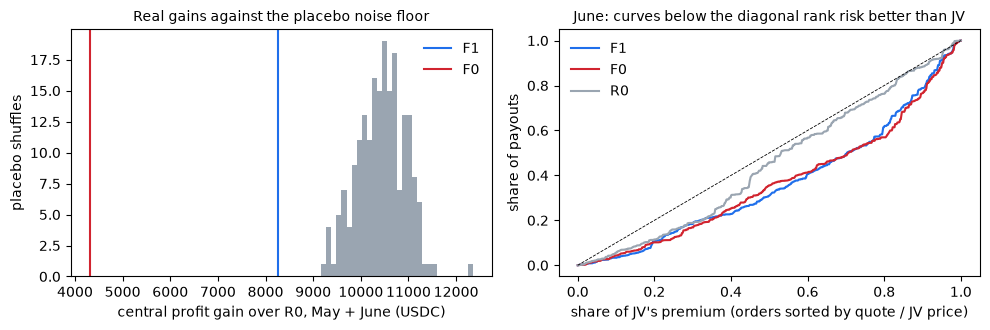

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(placebo_gain, bins=30, color="#9aa5b1")
for m, colour in [("F1", "#1f6feb"), ("F0", "#d1242f")]:
    axes[0].axvline(DIFF.loc[(m, "R0", CENTRAL, "May+June"), "difference"], color=colour, label=m)
axes[0].set_xlabel("central profit gain over R0, May + June (USDC)")
axes[0].set_ylabel("placebo shuffles")
axes[0].set_title("Real gains against the placebo noise floor", fontsize=10)
axes[0].legend(frameon=False)
t = panels["2026-06"]
for m, colour in [("F1", "#1f6feb"), ("F0", "#d1242f"), ("R0", "#9aa5b1")]:
    A, pay = t.q_C0.to_numpy(), t.realizedProfit_USDC.to_numpy()
    order, gid = tie_groups(t[f"q_{m}"].to_numpy() / A)
    x = np.r_[0, np.cumsum(np.bincount(gid, weights=A[order])) / A.sum()]
    y = np.r_[0, np.cumsum(np.bincount(gid, weights=pay[order])) / pay.sum()]
    axes[1].plot(x, y, color=colour, label=m)
axes[1].plot([0, 1], [0, 1], color="black", lw=0.6, ls="--")
axes[1].set_xlabel("share of JV's premium (orders sorted by quote / JV price)")
axes[1].set_ylabel("share of payouts")
axes[1].set_title("June: curves below the diagonal rank risk better than JV", fontsize=10)
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

**Post-hoc diagnostic, not part of the selection rule** (added after the declared placebo check ran; it changes no selection).
As declared, each placebo keeps F1's floor at fair value. A shuffled shape often puts a risky order below its fair value,
so the floor lifts it back up: that raises the placebo's total price and hands it back part of fair value's ranking.
The cell below repeats the same 200 shuffles and also scores them *without* the floor. If the placebo gains disappear
without the floor, the noise floor above measures the floor's price-level effect, not chance alone.

In [30]:
rng_check = np.random.default_rng(SEED)                                # same seed, so the same 200 shuffles
r0_total, check = mj.q_R0.sum(), []
for _ in range(SETTINGS["n_placebo"]):
    band = mj.p_ref.to_numpy() * shuffle_within(shape_mj, groups_mj, rng_check)
    quote = np.maximum(band, mj.fv.to_numpy())
    check.append({"gain_with_floor": central_profit(quote, A_mj, pay_mj) - base_r0,
                  "gain_without_floor": central_profit(band, A_mj, pay_mj) - base_r0,
                  "total_over_R0": quote.sum() / r0_total, "floor_raised_share": (mj.fv.to_numpy() > band).mean(),
                  "gini": gini(quote / A_mj, A_mj, pay_mj)})
check = pd.DataFrame(check)
assert np.allclose(check.gain_with_floor, placebo_gain), "the repeated shuffles differ from the declared placebo"
f1_band = mj.p_ref.to_numpy() * shape_mj
placebo_explained = pd.DataFrame({
    "placebo (mean of 200)": [check.gain_with_floor.mean(), check.gain_without_floor.mean(), check.total_over_R0.mean(),
                              check.floor_raised_share.mean(), check.gini.mean()],
    "F1": [central_profit(mj.q_F1.to_numpy(), A_mj, pay_mj) - base_r0, central_profit(mj.q_F1nf.to_numpy(), A_mj, pay_mj) - base_r0,
           mj.q_F1.sum() / r0_total, (mj.fv.to_numpy() > f1_band).mean(), gini(mj.q_F1.to_numpy() / A_mj, A_mj, pay_mj)]},
    index=["central gain vs R0, with floor", "central gain vs R0, without floor", "total quote / R0 total",
           "share of orders raised by the floor", "Gini (May+June pooled)"])
placebo_explained["label"] = "post-hoc diagnostic, not part of the selection rule"
placebo_explained.to_csv(OUT3 / "placebo_explained.csv")
print("placebo_explained.csv: post-hoc diagnostic, not part of the selection rule")
print(placebo_explained.drop(columns="label").round(4).to_string())

placebo_explained.csv: post-hoc diagnostic, not part of the selection rule
                                     placebo (mean of 200)         F1
central gain vs R0, with floor                  10434.0285  8257.5429
central gain vs R0, without floor               -5926.7484  3756.2924
total quote / R0 total                              1.0585     0.9917
share of orders raised by the floor                 0.3468     0.1543
Gini (May+June pooled)                              0.2023     0.2422


### 9.7 Robustness (reported, nothing retuned)

The same comparison with the top 1% of orders by notional removed (C2 rematched on the remaining orders), by pre-trade
60-minute volatility tercile (cut points from each fold's training orders), and on trending versus quiet days (top quarter
of absolute daily BTC moves among completed training days). Trending days are a retrospective slice only: a day's move is
not known when its orders are quoted.

In [31]:
ROB_MODELS = ["R0", "F0", "F1", "M", "S"]


def central_gain(t, m, versus):
    A, pay = t.q_C0.to_numpy(), t.realizedProfit_USDC.to_numpy()
    P = t[f"q_{m}"].to_numpy()
    Q = A * P.sum() / A.sum() if versus == "own C2" else t[f"q_{versus}"].to_numpy()
    return central_profit(P, A, pay) - central_profit(Q, A, pay)


def gains_table(subsets):
    rows = []
    for label, parts in subsets.items():
        for m in ROB_MODELS:
            rows.append({"slice": label, "model": m, **{f"vs {v}": sum(central_gain(t, m, v) for t in parts if len(t))
                                                        for v in ["C0", "own C2", "R0"]}})
    return pd.DataFrame(rows)


def drop_top_notional(t):
    order = np.lexsort((t.row.to_numpy(), -t.notional.to_numpy()))     # largest notional first, ties by row
    return t.drop(t.index[order[: int(np.ceil(0.01 * len(t)))]])


daily_close = candles.set_index("open_time").close.resample("D").last()
daily_move = np.log(daily_close).diff().abs()
slices = {"May+June, all orders": [panels["2026-05"], panels["2026-06"]],
          "May+June, top 1% notional removed": [drop_top_notional(panels[m]) for m in ["2026-05", "2026-06"]],
          "July, top 1% notional removed": [drop_top_notional(panels["2026-07"])]}
for month in FOLDS:
    fit, t, cut = folds[month]["fit"], panels[month], pd.Timestamp(FOLDS[month]["cutoff"])
    q = np.quantile(fit.rv_60, [1 / 3, 2 / 3])
    terc = np.digitize(t.rv_60, q)
    q75 = daily_move[(daily_move.index >= "2026-01-02") & (daily_move.index < cut)].quantile(0.75)
    trend = t.day.map(daily_move).to_numpy() >= q75
    for i, name in enumerate(["calm", "middle", "volatile"]):
        slices.setdefault(f"{name} tercile, May+June" if month != "2026-07" else f"{name} tercile, July", []).append(t[terc == i])
    slices.setdefault("trending days, May+June" if month != "2026-07" else "trending days, July", []).append(t[trend])
    slices.setdefault("quiet days, May+June" if month != "2026-07" else "quiet days, July", []).append(t[~trend])
robust = gains_table(slices)
robust.to_csv(OUT3 / "robustness.csv", index=False)
print(robust.pivot(index="slice", columns="model", values="vs C0").round(0).to_string())
print("\ngain vs own C2:")
print(robust.pivot(index="slice", columns="model", values="vs own C2").round(0).to_string())

model                                  F0      F1        M       R0        S
slice                                                                       
July, top 1% notional removed       415.0 -1619.0  11411.0 -13198.0  10036.0
May+June, all orders               1770.0  5717.0  12779.0  -2540.0   9746.0
May+June, top 1% notional removed  2020.0  5304.0  12212.0  -3167.0   8998.0
calm tercile, July                 3056.0  1180.0  10460.0 -10028.0   9538.0
calm tercile, May+June             2745.0  3678.0   6003.0    999.0   6388.0
middle tercile, July              -3315.0 -2933.0  -1013.0  -3499.0    177.0
middle tercile, May+June          -1066.0  1108.0   2025.0    548.0   4037.0
quiet days, July                  -2876.0 -3435.0   4480.0 -11857.0   3981.0
quiet days, May+June               -128.0  1205.0   5559.0  -3379.0   4898.0
trending days, July                1854.0   552.0   6302.0  -2730.0   6219.0
trending days, May+June            1898.0  4513.0   7220.0    838.0   4848.0

### 9.8 Price-level frontier, level-error regret and the volume sanity table

theta_level is the team's operating-price decision (default 0); these tables inform it and select nothing. The frontier
shows what a uniform shift of F1's band does to profit and to retained business. The regret table asks: if our reference
level were off by -20% to +20%, which theta_level loses least in the worst case (minimax regret; Bergemann & Schlag,
2011)? The sanity table shows how many extra orders a price cut would need just to keep today's profit.

In [32]:
def f1_requote(t, theta=0.0, eps=0.0):
    pr = t.p_ref.to_numpy() * (1 + eps)
    n = np.array([folds[m]["n"]["F1"] for m in t.month])
    return np.maximum(pr * np.clip(t.fv.to_numpy() / pr / n, *SETTINGS["band"]) * (1 + theta), t.fv.to_numpy())


THETAS, EPS = [-0.05, 0.0, 0.05, 0.10, 0.25], [-0.20, -0.10, 0.0, 0.10, 0.20]
front = []
for th in THETAS:
    P = f1_requote(mj, th)
    w2 = demand_weight(P / A_mj, ("conservative", 2.0))
    front.append({"theta_level": th, "bounds_vs_Pref": f"[{0.8 * (1 + th):.2f}, {1.2 * (1 + th):.2f}]",
                  "profit cons e=1": np.sum(demand_weight(P / A_mj, ("conservative", 1.0)) * (P - pay_mj)),
                  "profit cons e=2": np.sum(w2 * (P - pay_mj)), "orders kept (e=2)": w2.mean(),
                  "today's premium kept (e=2)": np.sum(w2 * A_mj) / A_mj.sum(),
                  "profit keep if r<=1": np.sum(demand_weight(P / A_mj, ("threshold", 1.0)) * (P - pay_mj))})
frontier = pd.DataFrame(front)
frontier.to_csv(OUT3 / "theta_frontier.csv", index=False)
print(frontier.round(3).to_string(index=False))

regret = pd.DataFrame({f"eps {e:+.0%}": [central_profit(f1_requote(mj, th, e), A_mj, pay_mj) for th in THETAS] for e in EPS},
                      index=[f"theta {th:+.2f}" for th in THETAS])
regret_gap = regret.max() - regret
regret_table = regret.round(0).assign(max_regret=regret_gap.max(axis=1).round(0))
regret_table.to_csv(OUT3 / "level_regret.csv")
print("\ncentral profit (May + June) if the reference level were off by eps, and each theta's worst-case regret:")
print(regret_table.to_string())

sanity = []
for label, P, C in [("May+June at JV's price", A_mj.sum(), pay_mj.sum()),
                    ("Feb-Jul book", lab.premiumAmount_USDC.sum(), lab.realizedProfit_USDC.sum())]:
    for x in (0.01, 0.05, 0.10):
        den = (1 - x) * P - C
        sanity.append({"book": label, "price cut": x, "volume needed": f"x{(P - C) / den:.2f}" if den > 0 else "no finite volume"})
print("\n" + pd.DataFrame(sanity).to_string(index=False))

 theta_level bounds_vs_Pref  profit cons e=1  profit cons e=2  orders kept (e=2)  today's premium kept (e=2)  profit keep if r<=1
       -0.05   [0.76, 1.14]        12870.556        13336.185              0.869                       0.844             9826.802
        0.00   [0.80, 1.20]        16662.267        16593.948              0.848                       0.824            11071.077
        0.05   [0.84, 1.26]        20727.006        19938.445              0.824                       0.799            12804.950
        0.10   [0.88, 1.32]        24931.309        23265.987              0.796                       0.770            11397.165
        0.25   [1.00, 1.50]        36090.138        30321.622              0.704                       0.670             7909.067



central profit (May + June) if the reference level were off by eps, and each theta's worst-case regret:
             eps -20%  eps -10%  eps +0%  eps +10%  eps +20%  max_regret
theta -0.05    7771.0   10303.0  13336.0   16595.0   19595.0     16985.0
theta +0.00   10010.0   13005.0  16594.0   20323.0   22855.0     13848.0
theta +0.05   12453.0   15969.0  19938.0   23683.0   25755.0     10884.0
theta +0.10   14884.0   18883.0  23266.0   26478.0   28280.0      7971.0
theta +0.25   21943.0   26853.0  30322.0   32603.0   34058.0         0.0

                  book  price cut    volume needed
May+June at JV's price       0.01            x1.13
May+June at JV's price       0.05            x2.40
May+June at JV's price       0.10 no finite volume
          Feb-Jul book       0.01            x1.17
          Feb-Jul book       0.05            x3.46
          Feb-Jul book       0.10 no finite volume


**Reading the frontier.** Under the conservative scenarios a higher price level always earns more here: with a 7%
margin, dropping a share of orders costs little while every kept order earns more, so the regret table's answer is the
highest theta in the grid. That is a corner of the grid, not an optimum, and it is exactly the "just charge more"
answer JV ruled out. Under the strict "keep only if r <= 1" rule the frontier peaks instead. The level choice therefore
cannot be read off the central scenario: it depends on JV's real conversion rule, which is why theta_level stays 0 unless
the team decides otherwise.

### 9.9 Where the payouts come from (descriptive only)

This table never feeds a feature or a choice: its groups are defined with hindsight. Orders are split into those whose
window contains a scheduled core release, those whose window contains one of the largest 0.5% of 15-minute BTC moves
that is *not* within the hour after a release, and the rest (the logic of `aman/checks/jump_attribution.py`, with candles
from the validation release as the ground rules require). It shows what the release term covers and what no quote-time
model can foresee: that is the case for the risk layer. Most news causes bursts of volatility rather than jumps
(Bajgrowicz, Scaillet & Treccani, 2016).

In [33]:
c15 = candles.set_index("open_time")
c15 = c15[(c15.index >= "2026-02-01") & (c15.index < "2026-08-01")]
bars15 = np.log(c15.close).resample("15min").last().diff().dropna().abs().rename("absr").to_frame()
bars15["start"] = bars15.index.to_numpy()
rel = np.sort(cal_core.to_numpy())


def near_release(t0):
    # True if the bar [t0, t0 + 15m) overlaps the hour after a core release.
    lo = np.searchsorted(rel, t0 - np.timedelta64(60, "m"), side="right")
    hi = np.searchsorted(rel, t0 + np.timedelta64(15, "m"), side="left")
    return hi > lo


def attribution_group(d, big):
    s, e = d.createdAt.to_numpy(), d.expirationDate.to_numpy()
    in_rel = np.searchsorted(rel, e, side="right") > np.searchsorted(rel, s, side="right")
    u0 = big.start.to_numpy()
    in_big = (np.searchsorted(u0, e, side="left") > np.searchsorted(u0 + np.timedelta64(15, "m"), s, side="right")) & ~in_rel
    return np.select([in_rel, in_big], ["release in window", "big unscheduled move"], "neither")


def attribution_table(d, price):
    g = pd.DataFrame({"group": d.attr_group.to_numpy(), "p": price, "y": d.realizedProfit_USDC.to_numpy()}).groupby("group")
    return pd.DataFrame({"orders": g.size(), "premium_share": g.p.sum() / price.sum(),
                         "payout_share": g.y.sum() / d.realizedProfit_USDC.sum(), "loss_ratio": g.y.sum() / g.p.sum()})


bars15["near_rel"] = near_release(bars15.start.to_numpy())
top01 = bars15[bars15.absr >= bars15.absr.quantile(0.999)]
big_unsched = bars15[(bars15.absr >= bars15.absr.quantile(0.995)) & ~bars15.near_rel]
lab["attr_group"] = attribution_group(lab, big_unsched)
anchor = attribution_table(lab, lab.premiumAmount_USDC.to_numpy())
print(anchor.round(3).to_string())
assert len(top01) == 18 and top01.near_rel.sum() == 0, "anchor: 0 of the 18 largest 15-minute moves near a release"
for grp, want in [("release in window", (0.057, 0.085, 1.39)), ("big unscheduled move", (0.045, 0.088, 1.81))]:
    got = anchor.loc[grp, ["premium_share", "payout_share", "loss_ratio"]].to_numpy()
    assert abs(got[0] - want[0]) < 5e-4 and abs(got[1] - want[1]) < 5e-4 and abs(got[2] - want[2]) < 5e-3, f"anchor {grp}: {got}"
print(f"anchors reproduced: release 5.7% / 8.5% / 1.39; big unscheduled 4.5% / 8.8% / 1.81; "
      f"{top01.near_rel.sum()} of the {len(top01)} largest 15-minute moves within an hour of a release")

attr_rows = []
for month, t in panels.items():
    t = t.merge(lab[["row", "attr_group"]], on="row")
    for version, d in [("all orders", t), ("without the 10 largest losses", t.drop((t.realizedProfit_USDC - t.q_C0).nlargest(10).index))]:
        for m in ["C0", SELECTED]:
            tab = attribution_table(d, d[f"q_{m}"].to_numpy()).reset_index()
            attr_rows.append(tab.assign(month=month, version=version, model=m))
attribution = pd.concat(attr_rows, ignore_index=True)[["month", "version", "model", "group", "orders", "premium_share", "payout_share", "loss_ratio"]]
attribution.to_csv(OUT3 / "payout_attribution.csv", index=False)
print(attribution.round(3).to_string(index=False))

                      orders  premium_share  payout_share  loss_ratio
group                                                                
big unscheduled move     243          0.045         0.088       1.814
neither                 6629          0.898         0.827       0.856
release in window        278          0.057         0.085       1.391
anchors reproduced: release 5.7% / 8.5% / 1.39; big unscheduled 4.5% / 8.8% / 1.81; 0 of the 18 largest 15-minute moves within an hour of a release


  month                       version model                group  orders  premium_share  payout_share  loss_ratio
2026-05                    all orders    C0 big unscheduled move      22          0.029         0.032       0.887
2026-05                    all orders    C0              neither     915          0.931         0.940       0.826
2026-05                    all orders    C0    release in window      28          0.039         0.029       0.592
2026-05                    all orders    F1 big unscheduled move      22          0.040         0.032       0.626
2026-05                    all orders    F1              neither     915          0.917         0.940       0.803
2026-05                    all orders    F1    release in window      28          0.043         0.029       0.517
2026-05 without the 10 largest losses    C0 big unscheduled move      22          0.031         0.040       0.887
2026-05 without the 10 largest losses    C0              neither     905          0.928 

In [34]:
june, july = attribution[attribution.month == "2026-06"], attribution[attribution.month == "2026-07"]
pick = lambda d, model, grp, col, ver="all orders": d[(d.model == model) & (d.group == grp) & (d.version == ver)][col].iloc[0]
print(f"June: big unscheduled moves carry {pick(june, 'C0', 'big unscheduled move', 'premium_share'):.1%} of JV's premium but "
      f"{pick(june, 'C0', 'big unscheduled move', 'payout_share'):.1%} of payouts (loss ratio {pick(june, 'C0', 'big unscheduled move', 'loss_ratio'):.2f} "
      f"at JV's price, {pick(june, SELECTED, 'big unscheduled move', 'loss_ratio'):.2f} at {SELECTED}'s).")
print(f"July: release windows carry {pick(july, 'C0', 'release in window', 'premium_share'):.1%} of premium and "
      f"{pick(july, 'C0', 'release in window', 'payout_share'):.1%} of payouts (loss ratio {pick(july, 'C0', 'release in window', 'loss_ratio'):.2f} "
      f"at JV's price, {pick(july, SELECTED, 'release in window', 'loss_ratio'):.2f} at {SELECTED}'s; "
      f"{pick(july, 'C0', 'release in window', 'loss_ratio', 'without the 10 largest losses'):.2f} without the 10 largest losses).")

June: big unscheduled moves carry 9.8% of JV's premium but 19.2% of payouts (loss ratio 1.84 at JV's price, 1.68 at F1's).
July: release windows carry 8.6% of premium and 14.7% of payouts (loss ratio 1.64 at JV's price, 1.57 at F1's; 1.11 without the 10 largest losses).


**Reading the attribution.** The large unscheduled moves sit almost entirely in June, and no quote-time model can
foresee them: F1 charges them a little more than JV does, but their loss ratio stays far above one. Release windows are
foreseeable, and the release term lifts their price, yet in July they still lost money. Both points argue for the risk
layer (exposure caps and hedging) rather than a bigger pricing model.

## 10. Phase 4 — extensions, tested against a closed registry

Every candidate was written into `team_scorecard/phase4_registry.csv` **before** any run: a one-line hypothesis, the
exact formula, the number of added parameters, the data source, the availability lag and the missing-value fallback.
Nothing outside that list is tested, and every run (passed, failed or not run) is logged in
`team_scorecard/phase4_trials.csv` with its skill gain per product length. We are an LLM-assisted team searching for
features, so we guard against our own data snooping: a closed list with hypotheses and parameter counts (Tang et al.,
2025), a log of failures (Xia et al., 2026), and a placebo that shifts each feature by whole weeks, because many
"detections" are false when many tests are run (Bajgrowicz, Scaillet & Treccani, 2016).

**The rule** (fixed in the plan): a feature enters the move model only if its May-June forecast skill beats the core
engine by at least 0.005 in at least 5 of the 7 product lengths, it beats at least 18 of 20 week-shifted copies of itself,
the final-quote Gini does not fall, and every commercial guard holds; if its paired profit difference with the core
includes zero, we keep the core. At most one feature is adopted. With 58-75% of F1's quotes clipped, a better forecast
may barely move final prices; nothing is added to compensate.

In [35]:
import time

registry = pd.read_csv(OUT3 / "phase4_registry.csv")
LENGTH_LABELS = [f"{t / 3600:g}h" for t in DURATIONS_S]
SKILL_FOLDS = [("2026-05", "2026-05-01", "2026-06-01"), ("2026-06", "2026-06-01", "2026-07-01")]
trials = []


def log_trial(reg_id, step, period, gains=None, passed=None, result="", notes=""):
    row = {"run_id": len(trials) + 1, "timestamp_sgt": pd.Timestamp.now(tz="Asia/Singapore").strftime("%Y-%m-%d %H:%M"),
           "registry_id": reg_id, "step": step, "fold_or_period": period, "passed": passed, "result": result, "notes": notes}
    if gains is not None:
        row.update({f"gain_{lab}": g for lab, g in zip(LENGTH_LABELS, gains)})
        row["lengths_with_gain_>=0.005"] = int(np.sum(np.asarray(gains) >= 0.005))
        row["mean_gain"] = float(np.mean(gains))
    trials.append(row)


print(registry[["id", "candidate", "status"]].to_string(index=False))

   id                                                 candidate                                                             status
 4a-1                                                 VIX level                                     registered 16 Oct; not yet run
 4a-2                                    US 10-year yield shock                                     registered 16 Oct; not yet run
 4a-3                                   S&P 500 absolute return                                     registered 16 Oct; not yet run
 4a-4                           Binance funding rate (absolute)                                     registered 16 Oct; not yet run
 4a-5                     Deribit DVOL (BTC implied volatility)                                     registered 16 Oct; not yet run
 4a-6                 Crypto Fear & Greed distance from neutral                                     registered 16 Oct; not yet run
 4a-7                                    Fed broad dollar index not run: the series

### 10.1 The test machinery

A candidate engine is Maksim's engine with one extra pre-trade feature, refitted on the same training windows. Skill is
measured on identical May and June market windows (each month scored by the engine fitted before it), relative to a
training-fitted average-move model: gain = (deviance of the core engine - deviance of the candidate) / deviance of the
average-move model. Features are standardised inside each fit, and a missing value falls back to that fit's training
median, as declared in the registry.

In [36]:
def engine_matrix_x(mkt_x, cum_prof, k, t_min, extra, med):
    X = engine_matrix(mkt_x, cum_prof, k, t_min)
    cols = [np.where(np.isnan(e[k]), m, e[k]) for e, m in zip(extra, med)]   # declared fallback: training median
    return np.column_stack([X] + cols) if cols else X


def fit_engine_x(mkt_x, cutoff, extra, k_event):
    k_end = to_minute(mkt_x, cutoff) - 1
    profile, cum_prof = fit_tod_profile(mkt_x, 0, k_end)
    k_all = market_windows(0, k_end, 30)
    med = [float(np.nanmedian(e[k_all])) for e in extra]
    models = {}
    for t_s in DURATIONS_S:
        t = t_s // 60
        k = market_windows(0, k_end, t)
        pipe = make_pipeline(StandardScaler(), PoissonRegressor(alpha=0.0, max_iter=1000))
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            models[t_s] = pipe.fit(engine_matrix_x(mkt_x, cum_prof, k, t, extra, med), abs_move_bps(mkt_x, k, t))
    excess = release_excess_var(mkt_x, k_end)
    return {"mkt": mkt_x, "cum_prof": cum_prof, "models": models, "extra": extra, "med": med, "releases": len(excess),
            "jump_var_raw": max(float(np.mean(excess)), 0.0) if len(excess) else 0.0, "k_event": k_event}


def predict_move_x(eng, k, t_s, flag, k_event=None):
    base = np.empty(len(k))
    for t in np.unique(t_s):
        sel = t_s == t
        X = engine_matrix_x(eng["mkt"], eng["cum_prof"], k[sel], int(t) // 60, eng["extra"], eng["med"])
        base[sel] = eng["models"][int(t)].predict(X) / 1e4
    s2 = (base * SQRT_PI_2) ** 2 + jump_var(eng, k_event) * flag
    return np.sqrt(s2) / SQRT_PI_2


def skill_gains(extra=(), mkt_x=None):
    # Gain in forecast skill over the core engine, per product length, for May and June windows.
    mkt_x = mkt if mkt_x is None else mkt_x
    out = {}
    for month, cutoff, end in SKILL_FOLDS:
        eng_x, ke = fit_engine_x(mkt_x, cutoff, extra, k_event_choice[month]), k_event_choice[month]
        k_from, k_to, k_train = to_minute(mkt, cutoff), to_minute(mkt, end) - 1, to_minute(mkt, cutoff) - 1
        gains = []
        for t_s in DURATIONS_S:
            t = t_s // 60
            k = market_windows(k_from, k_to, t)
            y, ts = abs_move_bps(mkt, k, t), np.full(len(k), t_s)
            avg = abs_move_bps(mkt, market_windows(0, k_train, t), t).mean()        # training-fitted average move
            d_base = poisson_deviance(y, np.full(len(k), avg)).mean()
            d_core = poisson_deviance(y, predict_move(engines[cutoff], mkt, k, ts, release_in_window(mkt, k, t), ke) * 1e4).mean()
            d_x = poisson_deviance(y, predict_move_x(eng_x, k, ts, release_in_window(mkt_x, k, t), ke) * 1e4).mean()
            gains.append((d_core - d_x) / d_base)
        out[month] = np.array(gains)
    out["mean"] = (out["2026-05"] + out["2026-06"]) / 2
    return out


def skill_rule(mean_gains):
    return int(np.sum(mean_gains >= 0.005)) >= 5


def run_skill(reg_id, step, extra=(), mkt_x=None, notes=""):
    g = skill_gains(extra, mkt_x)
    for period in ["2026-05", "2026-06"]:
        log_trial(reg_id, step, period, g[period], notes=notes)
    ok = skill_rule(g["mean"])
    log_trial(reg_id, step, "May-June mean", g["mean"], passed=ok,
              result="passes the skill rule" if ok else "fails the skill rule", notes=notes)
    return g, ok


def week_shifts(n_shift=20, seed=SEED):
    w_max = mkt["n"] // 10080 - 2
    return np.random.default_rng(seed).choice(np.arange(2, w_max + 1), size=n_shift, replace=False)



def fv_from_engine_x(eng_x, d, k_event):
    k, t_s = d.k.to_numpy(), d.productType.to_numpy()
    move = predict_move_x(eng_x, k, t_s, release_in_window(eng_x["mkt"], k, t_s // 60), k_event)
    return d.notional.to_numpy() * move / 2


def f1_variant_quotes(fv_fit, fv_test, month, p_ref_fit=None, p_ref_test=None):
    # F1 rebuilt on a different fair value (or reference): its own training-only n, same band and floor.
    fit, test = folds[month]["fit"], panels[month]
    pr_fit = fit.p_ref.to_numpy() if p_ref_fit is None else p_ref_fit
    pr_test = test.p_ref.to_numpy() if p_ref_test is None else p_ref_test
    n_var, status = solve_n(pr_fit, fv_fit, 1.0)
    return (quote_f1(pr_test, fv_test, n_var), "ok") if status == "ok" else (None, status)


def evaluate_variant(label, quotes):
    # The selection guards (a)-(d), plus the Phase 4 comparison with core F1 (May + June, central scenario).
    pm, pdr, wt = {}, {}, {}
    for month in ["2026-05", "2026-06"]:
        t = panels[month]
        A, pay, P = t.q_C0.to_numpy(), t.realizedProfit_USDC.to_numpy(), quotes[month]
        pm[month], pdr[month] = gini(P / A, A, pay), gini_draws(P / A, A, pay, BOOT[month])
        wt[month] = BOOT[month]["counts"] @ day_sums(A, BOOT[month])
    wA = [panels[mm].q_C0.sum() for mm in ["2026-05", "2026-06"]]
    g_point = (wA[0] * pm["2026-05"] + wA[1] * pm["2026-06"]) / sum(wA)
    g_lo = interval((wt["2026-05"] * pdr["2026-05"] + wt["2026-06"] * pdr["2026-06"]) / (wt["2026-05"] + wt["2026-06"]))[0]
    draws_v = {s: sum(profit_draws(panels[mm], quotes[mm], sc, BOOT[mm]) for mm in ["2026-05", "2026-06"]) for s, sc in SCENARIOS.items()}
    vs = lambda ref, s: draws_v[s] - mj_draws(ref, s)
    cp = corp(np.r_[quotes["2026-05"], quotes["2026-06"]], pay_mj, mj.scale.to_numpy())
    out = {"gini": g_point, "gini_lo90": g_lo, "(a) ranking": g_point > 0 and g_lo > 0,
           "(b) calibration": cp["DSC"] > corp_table.loc["R0", "DSC"] and cp["MCB"] <= corp_table.loc["R0", "MCB"] + 0.01 * corp_table.loc["R0", "UNC"],
           "(c) profit vs R0": (interval(vs("R0", CENTRAL))[1] >= 0) if underpowered else (interval(vs("R0", CENTRAL))[0] > -delta),
           "(d) no clear harm vs C0": all(interval(vs("C0", s))[1] >= 0 for s in SCENARIOS),
           "Gini not below F1": g_point >= gini_summary["F1"]["point"], "profit vs F1": float(np.mean(vs("F1", CENTRAL))),
           "profit vs F1 lo90": interval(vs("F1", CENTRAL))[0], "profit vs F1 hi90": interval(vs("F1", CENTRAL))[1]}
    out["beats core"] = all(out[k] for k in ["(a) ranking", "(b) calibration", "(c) profit vs R0", "(d) no clear harm vs C0",
                                             "Gini not below F1"]) and out["profit vs F1 lo90"] > 0
    return out


def guard_note(ev, extra=""):
    flags = ", ".join(f"{k} {'ok' if ev[k] else 'FAIL'}" for k in ["(a) ranking", "(b) calibration", "(c) profit vs R0",
                                                                  "(d) no clear harm vs C0", "Gini not below F1"])
    return (f"{flags}; Gini {ev['gini']:+.3f} vs F1 {gini_summary['F1']['point']:+.3f}; profit vs F1 {ev['profit vs F1']:+,.0f} "
            f"[{ev['profit vs F1 lo90']:+,.0f}, {ev['profit vs F1 hi90']:+,.0f}]{extra}")


def placebo_shift_test(rid, extra, real_mean, mkt_x=None):
    shifted_means, also_pass = [], 0
    for w in week_shifts():
        g = skill_gains([np.roll(e, int(w) * 10080) for e in extra], mkt_x)
        ok = skill_rule(g["mean"])
        log_trial(rid, f"placebo: shifted {w} weeks", "May-June mean", g["mean"], passed=ok)
        shifted_means.append(g["mean"].mean())
        also_pass += ok
    return int(np.sum(real_mean > np.array(shifted_means))), also_pass


ADOPTABLE = []                     # (registry id, mean skill gain, added parameters, needs a download)
VARIANT_QUOTES = {}                # quotes of every variant that reached the pricing guards (May, June)


def level_vs_allocation(quotes):
    # Level = quoted total / JV's total; allocation = central profit minus its own same-total flat change (C2).
    months = ["2026-05", "2026-06"]
    level = sum(quotes[mm].sum() for mm in months) / A_mj.sum()
    draws_d = sum(profit_draws(panels[mm], quotes[mm], SCENARIOS[CENTRAL], BOOT[mm]) - c2_draws(panels[mm], quotes[mm], SCENARIOS[CENTRAL], BOOT[mm])
                  for mm in months)
    point = 0.0
    for mm in months:
        A, pay = panels[mm].q_C0.to_numpy(), panels[mm].realizedProfit_USDC.to_numpy()
        point += central_profit(quotes[mm], A, pay) - central_profit(A * quotes[mm].sum() / A.sum(), A, pay)
    lo, hi = interval(draws_d)
    return {"quoted / JV (May+Jun)": level, "vs own C2": point, "lo90": lo, "hi90": hi}


def follow_up(rid, extra, mean_gains, raw=None):
    # After a candidate passes the skill rule: week-shift placebo, then the pricing guards and rule R2.
    beats, also_pass = placebo_shift_test(rid, extra, mean_gains.mean())
    log_trial(rid, "placebo summary", "May-June mean", passed=beats >= 18,
              result=f"beats {beats} of 20 shifted copies; {also_pass} shifted copies also pass the skill rule")
    print(f"{rid}: placebo - beats {beats} of 20 shifted copies; {also_pass} shifted copies also pass the skill rule")
    if beats < 18:
        return
    quotes = {}
    for month, cutoff, _end in SKILL_FOLDS:
        eng_x = fit_engine_x(mkt, cutoff, extra, k_event_choice[month])
        quotes[month], _ = f1_variant_quotes(fv_from_engine_x(eng_x, folds[month]["fit"], k_event_choice[month]),
                                             fv_from_engine_x(eng_x, panels[month], k_event_choice[month]), month)
    ev = evaluate_variant(rid, quotes)
    VARIANT_QUOTES[rid] = quotes
    share_fb = float(np.mean(np.isnan(raw[blind.k.to_numpy()]))) if raw is not None else 0.0
    covers = raw is None or not np.isnan(raw[blind.k.max()])
    ok = ev["beats core"] and share_fb <= 0.05 and covers
    log_trial(rid, "pricing guards", "May-June", passed=ok, result="passes every guard" if ok else "keeps core F1",
              notes=guard_note(ev, f"; blind fallback {share_fb:.1%}; covers blind period {covers}"))
    print(f"{rid}: pricing guards -> {'passes' if ok else 'keeps core F1'} ({guard_note(ev)})")
    if ok:
        ADOPTABLE.append((rid, float(mean_gains.mean()), 7, raw is not None))


print("candidate engines refit Maksim's engine with one extra feature; placebo shifts (weeks):", sorted(week_shifts()))

candidate engines refit Maksim's engine with one extra feature; placebo shifts (weeks): [np.int64(2), np.int64(3), np.int64(5), np.int64(7), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(17), np.int64(18), np.int64(23), np.int64(24), np.int64(25), np.int64(28), np.int64(30), np.int64(31), np.int64(33), np.int64(36), np.int64(37)]


### 10.2 Candidates 4c-1 to 4c-3 (built from our own data, no downloads)

**4c-1** jump share of last-hour variance, from bipower variation (Barndorff-Nielsen & Shephard, 2004).
**4c-2** a volatility-of-volatility proxy, the log realised kurtosis over the last 240 minutes (in the spirit of Du & Shen,
2025). **4c-3** PCE releases added to the single release-variance term (and to the profile's release exclusion).
The hypotheses are in the registry; each is tested alone.

In [37]:
def minute_features_from_candles(mkt):
    r = np.diff(mkt["logp"], prepend=mkt["logp"][0])
    a, k = np.abs(r), np.arange(mkt["n"])
    cum_bp = np.concatenate([[0.0], np.cumsum(np.r_[0.0, a[1:] * a[:-1]])])        # |r_i| x |r_(i-1)|
    cum_r4 = np.concatenate([[0.0], np.cumsum(r ** 4)])
    tail = lambda cum, h: np.where(k >= h, cum[k + 1] - cum[np.maximum(k + 1 - h, 0)], np.nan)
    rv60, bv60 = tail(mkt["cum_r2"], 60), np.pi / 2 * tail(cum_bp, 59)
    jump = np.where(rv60 > 0, np.maximum(rv60 - bv60, 0) / rv60, 0.0)
    s2, s4 = tail(mkt["cum_r2"], 240), tail(cum_r4, 240)
    rk = np.where(s2 > 0, 240 * s4 / np.where(s2 > 0, s2, 1) ** 2, 3.0)
    return jump, np.log(rk)


jump_share, log_rk = minute_features_from_candles(mkt)
mkt_pce = build_market(candles, load_releases(EXT / "macro_events_2026_checked.csv", CORE_EVENTS + ["PCE"]))
c_results = {}
t_start = time.time()
c_results["4c-1"] = run_skill("4c-1", "skill test", [jump_share])
c_results["4c-2"] = run_skill("4c-2", "skill test", [log_rk])
c_results["4c-3"] = run_skill("4c-3", "skill test", (), mkt_pce, notes=f"{len(mkt_pce['event_idx']) - len(mkt['event_idx'])} PCE releases added")
for rid, (g, ok) in c_results.items():
    print(f"{rid}: May-June mean gain per length {np.round(g['mean'], 4)} -> {'PASSES' if ok else 'fails'} the skill rule")
for rid, extra, mx in [("4c-1", [jump_share], None), ("4c-2", [log_rk], None)]:
    if c_results[rid][1]:
        follow_up(rid, extra, c_results[rid][0]["mean"])
print(f"({time.time() - t_start:.0f} s)")

4c-1: May-June mean gain per length [-0.      0.      0.0018  0.0019  0.0025  0.0017 -0.0009] -> fails the skill rule
4c-2: May-June mean gain per length [0.0034 0.005  0.0058 0.0057 0.0019 0.0024 0.0053] -> fails the skill rule
4c-3: May-June mean gain per length [-0.0002 -0.0005 -0.0001  0.0003 -0.      0.0003  0.0002] -> fails the skill rule
(2 s)


### 10.3 Candidates 4a-1 to 4a-6: daily market series (downloaded)

Each series is read from its snapshot in `aman/data_external/` and attached to every window with the availability lag
declared in the registry: a value is used only once it would have been known (for example, a US close from 22:00 UTC that
day, the 10-year yield one business day later, the last funding settlement, the last closed hourly DVOL bar, the previous
UTC day's Fear & Greed). A value older than its declared limit falls back to the training median. A source that could not
be downloaded is logged as "not run: data unavailable" and is not replaced by another source.

In [38]:
fetch_status = json.loads((EXT / "fetch_status.json").read_text()) if (EXT / "fetch_status.json").exists() else {}
gdelt_status_file = EXT / "fetch_status_gdelt.json"
fetch_status.update(json.loads(gdelt_status_file.read_text()) if gdelt_status_file.exists() else {})
WINDOW_START = (mkt["t0"] + pd.to_timedelta(np.arange(mkt["n"]) + 1, unit="min")).to_numpy()   # start of the window after minute k


def asof_feature(avail, values, max_age):
    # Latest value already available at each window start; NaN (-> training median) if none or older than max_age.
    order = np.argsort(np.asarray(avail, dtype="datetime64[ns]"))
    a, v = np.asarray(avail, dtype="datetime64[ns]")[order], np.asarray(values, dtype=float)[order]
    i = np.searchsorted(a, WINDOW_START, side="right") - 1
    out = np.where(i >= 0, v[np.maximum(i, 0)], np.nan)
    out[(i < 0) | (WINDOW_START - a[np.maximum(i, 0)] > np.timedelta64(pd.Timedelta(max_age)))] = np.nan
    return out


def daily_feature(name):
    d = pd.read_csv(EXT / f"{name}.csv")
    day = pd.to_datetime(d.iloc[:, 0])
    return day, d.iloc[:, 1].astype(float)


def build_4a(rid):
    if rid == "4a-1":
        day, v = daily_feature("fred_VIXCLS")
        return asof_feature(day + pd.Timedelta(hours=22), np.log(v), "7D")
    if rid == "4a-2":
        day, v = daily_feature("fred_DGS10")
        next_bday = day + pd.offsets.BDay(1)                                     # H.15 publishes the next business day
        return asof_feature(next_bday[1:] + pd.Timedelta(hours=22), np.abs(np.diff(v.to_numpy())), "7D")
    if rid == "4a-3":
        day, v = daily_feature("fred_SP500")
        return asof_feature(day[1:] + pd.Timedelta(hours=22), np.abs(np.diff(np.log(v.to_numpy()))), "7D")
    if rid == "4a-4":
        d = pd.read_csv(EXT / "binance_funding_BTCUSDC.csv")
        return asof_feature(pd.to_datetime(d.funding_time_utc) + pd.Timedelta(minutes=1), 1e4 * np.abs(d.funding_rate), "24h")
    if rid == "4a-5":
        d = pd.read_csv(EXT / "deribit_dvol_btc_hourly.csv")
        return asof_feature(pd.to_datetime(d.hour_start_utc) + pd.Timedelta(hours=1), np.log(d.close), "6h")
    if rid == "4a-6":
        d = pd.read_csv(EXT / "fear_greed_daily.csv")
        return asof_feature(pd.to_datetime(d.date_utc) + pd.Timedelta(days=1), np.abs(d.value - 50), "3D")


SOURCE = {"4a-1": "fred_VIXCLS", "4a-2": "fred_DGS10", "4a-3": "fred_SP500", "4a-4": "binance_funding_BTCUSDC",
          "4a-5": "deribit_dvol_btc_hourly", "4a-6": "fear_greed_daily"}
features_4a, a_results = {}, {}
for rid, src in SOURCE.items():
    st = fetch_status.get(src, {}).get("status")
    if st != "ok":
        log_trial(rid, "download", "-", passed=False, result="not run: data unavailable",
                  notes=fetch_status.get(src, {}).get("message", "no snapshot"))
        print(f"{rid}: not run: data unavailable ({src})")
        continue
    features_4a[rid] = build_4a(rid)
    a_results[rid] = run_skill(rid, "skill test", [features_4a[rid]])
    print(f"{rid}: May-June mean gain per length {np.round(a_results[rid][0]['mean'], 4)} -> "
          f"{'PASSES' if a_results[rid][1] else 'fails'} the skill rule")
    if a_results[rid][1]:
        follow_up(rid, [features_4a[rid]], a_results[rid][0]["mean"], raw=features_4a[rid])
log_trial("4a-7", "-", "-", passed=False, result="not run: the series is revised and no vintage is available in time")

4a-1: not run: data unavailable (fred_VIXCLS)
4a-2: not run: data unavailable (fred_DGS10)
4a-3: not run: data unavailable (fred_SP500)


4a-4: May-June mean gain per length [ 0.0002  0.0003  0.     -0.0007 -0.0032 -0.0042 -0.0077] -> fails the skill rule


4a-5: May-June mean gain per length [0.0015 0.0025 0.0057 0.0082 0.0177 0.0152 0.0103] -> PASSES the skill rule


4a-5: placebo - beats 18 of 20 shifted copies; 0 shifted copies also pass the skill rule


4a-5: pricing guards -> keeps core F1 ((a) ranking ok, (b) calibration ok, (c) profit vs R0 ok, (d) no clear harm vs C0 ok, Gini not below F1 FAIL; Gini +0.234 vs F1 +0.235; profit vs F1 -1,553 [-2,487, -771])


4a-6: May-June mean gain per length [-0.0001 -0.0004 -0.0006 -0.0007 -0.0013 -0.0005  0.0002] -> fails the skill rule


### 10.4 Candidates 4b1-1 and 4b1-2: GDELT news attention

Hourly counts of English-language articles matching "bitcoin" from the GDELT DOC 2.0 API (Leetaru & Schrodt, 2013), the
same query as Subham's file. Attention is the share of all monitored articles, (value + 1) / norm, compared with its median
in the same hour of the week over the previous four weeks. Only hours that end at least one hour before the window starts
are used. The snapshot is today's view of past counts, not a real-time record. News is used only for the *size* of the
move, never its direction. Kong et al. (2025) use a daily article count beside text to forecast volatility.

In [39]:
def gdelt_attention():
    g = pd.read_csv(EXT / "gdelt_bitcoin_hourly.csv", parse_dates=["hour_utc"])
    hours = pd.date_range("2025-12-01", "2026-10-16", freq="h")
    share = pd.Series(np.nan, index=hours)
    share.loc[g.hour_utc] = ((g.value + 1) / g.norm).to_numpy()
    lags = pd.concat([share.shift(168 * j) for j in (1, 2, 3, 4)], axis=1)          # same hour of week, previous 4 weeks
    med = lags.median(axis=1).where(lags.notna().sum(axis=1) >= 2)
    a1 = np.log(share) - np.log(med)                                                 # NaN -> declared fallback below
    a24 = a1.rolling(24, min_periods=12).mean()
    return a1, a24


def by_window_hour(series):
    # Hour H starting at floor(window start - 2 h): it ends at least one hour before the window starts.
    h = pd.DatetimeIndex(WINDOW_START - np.timedelta64(2, "h")).floor("h")
    return series.reindex(h).to_numpy()


b_results, features_4b = {}, {}
st = fetch_status.get("gdelt_bitcoin_hourly", {})
if st.get("status") != "ok":
    for rid in ["4b1-1", "4b1-2"]:
        log_trial(rid, "download", "-", passed=False, result="not run: data unavailable",
                  notes=f"hourly spacing {st.get('hourly_spacing')}, Feb-Oct coverage {st.get('coverage_feb_oct')}, {st.get('message', '')}")
    print("4b1: not run: data unavailable", st)
else:
    a1, a24 = gdelt_attention()
    for rid, series in [("4b1-1", a1), ("4b1-2", a24)]:
        raw = by_window_hour(series)
        features_4b[rid] = (raw, np.isnan(raw))                                     # keep the fallback flags for rule R2
        b_results[rid] = run_skill(rid, "skill test", [np.nan_to_num(raw, nan=0.0)])  # declared fallback: 0 = normal attention
        print(f"{rid}: May-June mean gain per length {np.round(b_results[rid][0]['mean'], 4)} -> "
              f"{'PASSES' if b_results[rid][1] else 'fails'} the skill rule")
        if b_results[rid][1]:
            follow_up(rid, [np.nan_to_num(raw, nan=0.0)], b_results[rid][0]["mean"], raw=raw)
log_trial("4b2", "-", "-", passed=False, result="not run without Aman's OK")

4b1: not run: data unavailable {'status': 'failed', 'message': 'no answer for 2026-01-01 after retries', 'calls': 1}


### 10.5 Candidate 4c-4: implied over realised volatility in the reference model

This one changes our estimate of JV's price, not the move forecast. Bitcoin's variance risk premium is higher when
volatility is low (Almeida et al., 2025), so JV's charged-vol ratio may track log(DVOL / RV_1d). Under the inner time
order, a Ridge reference with this extra input must beat the declared reference choice on the calibration month by at least
0.5 points of weighted error before it can go further.

In [40]:
def ref_design_x(d, dur_cols, x):
    return np.column_stack([ref_design(d, dur_cols), x])


def dvol_ratio(d, dvol=None):
    raw = (features_4a["4a-5"] if dvol is None else dvol)[d.k.to_numpy()]          # log DVOL at the order's last closed minute
    return np.log(np.exp(raw) / 100) - np.log(d.rv_1d.to_numpy())


def dvol_reference(fit, alpha, dvol=None):
    # Ridge reference with log(DVOL / RV_1d) as an extra input; returns a pricing function and its fallback median.
    x_fit = dvol_ratio(fit, dvol)
    med = float(np.nanmedian(x_fit))
    fill = lambda x: np.where(np.isnan(x), med, x)
    dur_cols = sorted(fit.productType.unique())
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(
        ref_design_x(fit, dur_cols, fill(x_fit)), np.log((fit.premiumAmount_USDC / fit.scale) / fit.rv_1d),
        ridge__sample_weight=(fit.notional / fit.notional.mean()).to_numpy())
    raw = lambda d: d.scale.to_numpy() * np.exp(model.predict(ref_design_x(d, dur_cols, fill(dvol_ratio(d, dvol))))) * d.rv_1d.to_numpy()
    last = fit.month.isin(sorted(fit.month.unique())[-SETTINGS["level_months"]:]).to_numpy()
    level = fit.premiumAmount_USDC.to_numpy()[last].sum() / raw(fit[last]).sum()
    return lambda d: raw(d) * level


def dvol_inner_check(dvol=None):
    rows = []
    for month, f in FOLDS.items():
        if f["inner"] is None:
            continue
        cal = lab[(lab.month == f["inner"][:7]) & (lab.closedAt < pd.Timestamp(f["cutoff"]))]
        t, (kind, value) = ref_tables[month], ref_choice[month]
        declared = t[(t.kind == kind) & (t.value == value)].weighted_abs_error.iloc[0]
        errs = {a: ref_errors(dvol_reference(eligible(f["inner"]), a, dvol)(cal), cal)["weighted_abs_error"] for a in SETTINGS["ridge_alphas"]}
        best = min(errs, key=errs.get)
        rows.append({"fold": month, "declared_spec": f"{kind} {value}", "declared_error": declared, "alpha": best,
                     "with_dvol": errs[best], "improvement_points": 100 * (declared - errs[best]),
                     "passes": declared - errs[best] >= SETTINGS["ridge_margin"]})
    return pd.DataFrame(rows)


if "4a-5" not in features_4a:
    log_trial("4c-4", "download", "-", passed=False, result="not run: data unavailable", notes="needs the DVOL snapshot")
else:
    c4 = dvol_inner_check()
    print(c4.round(4).to_string(index=False))
    c4_pass = bool(c4.passes.any())
    log_trial("4c-4", "inner reference check", "June and July folds", passed=c4_pass,
              result="improves the reference by >= 0.5 points in a fold" if c4_pass else "no fold improves by 0.5 points",
              notes="; ".join(f"{r.fold}: {r.improvement_points:+.2f} points" for r in c4.itertuples()))
    if c4_pass:
        real = c4.improvement_points.mean()
        shifted = []
        for w in week_shifts():
            s = dvol_inner_check(np.roll(features_4a["4a-5"], int(w) * 10080))
            shifted.append(s.improvement_points.mean())
            log_trial("4c-4", f"placebo: shifted {w} weeks", "June and July folds", passed=bool(s.passes.any()),
                      notes=f"mean improvement {s.improvement_points.mean():+.2f} points")
        beats = int(np.sum(real > np.array(shifted)))
        also = int(np.sum([x >= 100 * SETTINGS["ridge_margin"] for x in shifted]))
        log_trial("4c-4", "placebo summary", "June and July folds", passed=beats >= 18,
                  result=f"beats {beats} of 20 shifted copies; {also} shifted copies also improve the reference by >= 0.5 points on average")
        print(f"4c-4: placebo - beats {beats} of 20 shifted copies; {also} shifted copies also improve by >= 0.5 points on average")
        if beats >= 18:
            quotes, audit_rows = {}, []
            for month in ["2026-05", "2026-06"]:
                f, use = FOLDS[month], c4.set_index("fold").passes.get(month, False)
                if use:                                                              # May has no inner split: declared default
                    price = dvol_reference(eligible(f["cutoff"]), c4.set_index("fold").alpha[month])
                    p_fit, p_test = price(folds[month]["fit"]), price(panels[month])
                else:
                    p_fit, p_test = folds[month]["fit"].p_ref.to_numpy(), panels[month].p_ref.to_numpy()
                audit_rows.append({"month": month, **ref_errors(p_test, panels[month])})
                quotes[month], _ = f1_variant_quotes(folds[month]["fit"].fv.to_numpy(), panels[month].fv.to_numpy(), month, p_fit, p_test)
            audit_c4 = pd.DataFrame(audit_rows)
            audit_ok = bool(((audit_c4.bias.abs() <= SETTINGS["audit_bias"]) & (audit_c4.weighted_abs_error <= SETTINGS["audit_wae"])).all())
            ev = evaluate_variant("4c-4", quotes)
            VARIANT_QUOTES["4c-4"] = quotes
            x_blind = dvol_ratio(blind)
            share_fb, covers = float(np.mean(np.isnan(x_blind))), not np.isnan(x_blind[np.argmax(blind.createdAt.to_numpy())])
            ok = ev["beats core"] and audit_ok and share_fb <= 0.05 and covers
            log_trial("4c-4", "audit and pricing guards", "May-June", passed=ok, result="passes every guard" if ok else "keeps core F1",
                      notes=guard_note(ev, f"; audit {'ok' if audit_ok else 'FAIL'}; blind fallback {share_fb:.1%}; covers blind period {covers}"))
            print(audit_c4.round(4).to_string(index=False))
            print(f"4c-4: audit and pricing guards -> {'passes' if ok else 'keeps core F1'} ({guard_note(ev)})")
            if ok:
                ADOPTABLE.append(("4c-4", np.nan, 1, True))

   fold declared_spec  declared_error  alpha  with_dvol  improvement_points  passes
2026-06        dur 25          0.2095      1     0.1830              2.6571    True
2026-07     ridge 100          0.2064    100     0.1952              1.1201    True

4c-4: placebo - beats 18 of 20 shifted copies; 10 shifted copies also improve by >= 0.5 points on average


  month    bias  weighted_abs_error
2026-05 -0.0159              0.2139
2026-06 -0.2071              0.2073
4c-4: audit and pricing guards -> keeps core F1 ((a) ranking ok, (b) calibration ok, (c) profit vs R0 FAIL, (d) no clear harm vs C0 ok, Gini not below F1 FAIL; Gini +0.232 vs F1 +0.235; profit vs F1 -6,745 [-9,911, -3,922])


### 10.6 Candidate 4d: per-length payout calibration (F1d)

This adjusts how fair value maps to payouts, not the move forecast, so the market-skill rule does not apply. Each fold
estimates, from earlier settled orders and their out-of-fold fair values only, a payout / fair-value factor per product
length, shrunk toward one with weight n / (n + 100). F1 is then rebuilt on the adjusted fair value with its own
training-only n. It must pass the commercial guards, keep a Gini no lower than F1's, and earn more than F1 with a paired
interval above zero; otherwise F1 stays.

In [41]:
oof_fv = wf.set_index("row").fv                                                   # out-of-fold fair values (Phase 2 walk-forward)
d_quotes, d_ok = {}, True
for month, f in FOLDS.items():
    fit = folds[month]["fit"]
    g = pd.DataFrame({"len": fit.productType, "pay": fit.realizedProfit_USDC, "fv": fit.row.map(oof_fv)}).groupby("len").sum()
    n_g = fit.groupby("productType").size()
    w = n_g / (n_g + 100)
    factor = (w * g.pay / g.fv + (1 - w)).to_dict()
    adj = lambda d: d.fv.to_numpy() * d.productType.map(lambda t: factor.get(t, 1.0)).to_numpy()
    q, status = f1_variant_quotes(adj(fit), adj(panels[month]), month)
    if q is None:
        d_ok = False
        log_trial("4d", "normalisation", month, passed=False, result=f"F1d cannot be normalised: {status}")
        break
    d_quotes[month] = q
if d_ok:
    d_eval = evaluate_variant("F1d", d_quotes)
    VARIANT_QUOTES["4d"] = d_quotes
    log_trial("4d", "pricing guards", "May-June", passed=d_eval["beats core"],
              result="passes every guard" if d_eval["beats core"] else "keeps core F1", notes=guard_note(d_eval))
    print(f"4d: pricing guards -> {'passes' if d_eval['beats core'] else 'keeps core F1'} ({guard_note(d_eval)})")
    if d_eval["beats core"]:
        ADOPTABLE.append(("4d", np.nan, 7, False))

4d: pricing guards -> keeps core F1 ((a) ranking ok, (b) calibration ok, (c) profit vs R0 ok, (d) no clear harm vs C0 ok, Gini not below F1 FAIL; Gini +0.222 vs F1 +0.235; profit vs F1 -336 [-2,189, +1,097])


### 10.7 Placebo, pricing guards and the adoption decision

A candidate that passes the skill rule must then beat at least 18 of 20 copies of itself shifted by a random whole number
of weeks (at least two): the shift keeps the hour-of-week pattern but breaks the link between the feature and the moves.
Only then are the pricing guards run. At most one feature is adopted (rule R1), and an external feature must cover the
blind period and need its fallback on no more than 5% of blind orders (rule R2).

In [42]:
NOT_RUN_TIME = []            # registry ids stopped by the three-hour time box (filled in only if time ran out)
for rid in NOT_RUN_TIME:
    log_trial(rid, "-", "-", passed=False, result="not run (time)")

# Rule R1: at most one feature. Largest mean skill gain; then fewer parameters; then no download.
if len(ADOPTABLE) == 1:
    ADOPTED = ADOPTABLE[0][0]
elif len(ADOPTABLE) > 1 and all(np.isfinite(a[1]) for a in ADOPTABLE):
    ADOPTED = sorted(ADOPTABLE, key=lambda a: (-a[1], a[2], a[3]))[0][0]
else:
    ADOPTED = None if not ADOPTABLE else "team decision needed"
trial_log = pd.DataFrame(trials)
trial_log.to_csv(OUT3 / "phase4_trials.csv", index=False)
skill_rows = trial_log[(trial_log.step == "skill test") & (trial_log.fold_or_period == "May-June mean")]
feature_table = registry[~registry.id.str.startswith("R")][["id", "candidate", "added_parameters"]].merge(
    skill_rows[["registry_id"] + [f"gain_{l}" for l in LENGTH_LABELS] + ["lengths_with_gain_>=0.005", "mean_gain", "passed"]],
    left_on="id", right_on="registry_id", how="left").drop(columns="registry_id").rename(columns={"passed": "skill_rule"})
feature_table["outcome"] = feature_table.id.map(trial_log.groupby("registry_id").result.last())
feature_table.to_csv(OUT3 / "phase4_feature_table.csv", index=False)
with pd.option_context("display.max_colwidth", 46):
    print(feature_table.drop(columns="added_parameters").round(4).to_string(index=False))
print(f"\n{len(trial_log)} runs logged in phase4_trials.csv")
level_alloc = pd.DataFrame({"F1": level_vs_allocation({mm: panels[mm].q_F1.to_numpy() for mm in ["2026-05", "2026-06"]}),
                            **{rid: level_vs_allocation(q) for rid, q in VARIANT_QUOTES.items()}}).T
level_alloc.to_csv(OUT3 / "phase4_level_vs_allocation.csv")
print("\nlevel vs allocation, May + June, central scenario (variants that reached the pricing guards):")
print(level_alloc.round(3).to_string())
PHASE4_VERDICT = f"{ADOPTED} adopted" if ADOPTED else "JV's suggested macro and sentiment data tested; none adopted"
print("Phase 4:", PHASE4_VERDICT)

   id                                                 candidate  gain_0.5h  gain_1h  gain_2h  gain_4h  gain_8h  gain_12h  gain_24h  lengths_with_gain_>=0.005  mean_gain skill_rule                                                            outcome
 4a-1                                                 VIX level        NaN      NaN      NaN      NaN      NaN       NaN       NaN                        NaN        NaN        NaN                                          not run: data unavailable
 4a-2                                    US 10-year yield shock        NaN      NaN      NaN      NaN      NaN       NaN       NaN                        NaN        NaN        NaN                                          not run: data unavailable
 4a-3                                   S&P 500 absolute return        NaN      NaN      NaN      NaN      NaN       NaN       NaN                        NaN        NaN        NaN                                          not run: data unavailable
 4a-4       

## 11. Phase 5 — final fit and blind prices

**Team decision (16 Oct regroup): model F1, theta_level = 0, band 0.8-1.2.** Phase 4 adopted no feature, so F1 keeps
the settings chosen for the July fold (on June data). Everything below is refitted once on all labels created **and**
settled before 2026-07-31 17:11:00 UTC, and on market windows ending before that time. The specification was
**locked at 2026-10-16 04:46 SGT** (`model_params.json`: `spec_locked`, `locked_at` and the SHA-256 of `validation_predictions.csv`),
before the 544-row reference check in section 14 was first run.

In [43]:
assert ADOPTED is None, "a Phase 4 feature was adopted: stop after the Phase 4 report"
FINAL_STATUS = "final"
SPEC_LOCKED_AT = "2026-10-16 04:46 SGT"                 # when the team's decision was applied (metadata: never used by a price)
TEAM_DECISION = "16 Oct regroup: model F1, theta_level = 0, band 0.8-1.2"
final_fit = eligible(FINAL_CUTOFF).copy()
cutoff_exclusions = {
    "resolved, created before the cutoff but settled after it": int(((lab.createdAt < FINAL_CUTOFF) & (lab.closedAt >= FINAL_CUTOFF)).sum()),
    "resolved, created at or after the cutoff": int((lab.createdAt >= FINAL_CUTOFF).sum()),
    "unresolved (no payout in the file)": int(train.realizedProfit_USDC.isna().sum())}
final_engine = fit_engine(mkt, FINAL_CUTOFF, k_event=k_event_choice["2026-07"])
final_ref = fit_reference(final_fit, *ref_choice["2026-07"])
final_fit["fv"] = fair_value(final_engine, mkt, final_fit)
final_fit["p_ref"] = reference_price(final_ref, final_fit)
final_n, n_status = solve_n(final_fit.p_ref.to_numpy(), final_fit.fv.to_numpy(), 1.0)
assert n_status == "ok", n_status
FINAL = {"engine": final_engine, "ref": final_ref, "n": final_n, "lam": 1.0, "theta": 0.0, "k_event": k_event_choice["2026-07"]}
print(f"final fit: {len(final_fit):,} labels; excluded: {cutoff_exclusions}")
print(f"engine windows (30 min): {final_engine['n_windows'][1800]:,}; releases seen {final_engine['releases']}, "
      f"release term {np.sqrt(jump_var(final_engine)) * 1e4:.1f} bps (k_event {FINAL['k_event']})")
print(f"reference: {ref_choice['2026-07'][0]} {ref_choice['2026-07'][1]}, level factor {final_ref['level_factor']:.4f} "
      f"over {', '.join(final_ref['level_months'])}; n = {final_n:.4f}")

final fit: 7,132 labels; excluded: {'resolved, created before the cutoff but settled after it': 17, 'resolved, created at or after the cutoff': 1, 'unresolved (no payout in the file)': 54}
engine windows (30 min): 58,953; releases seen 19, release term 57.3 bps (k_event 0)
reference: ridge 100, level factor 1.0248 over 2026-05, 2026-06, 2026-07; n = 0.9933


### 11.1 `price_orders`: one row in, one price out

The function takes a file in the blind format and uses **only** these columns: `createdAt`, `optionType`,
`productType`, `quantity_BTC`, `strikePrice` and, for the multiplier display only, `apiBasePrice_per_BTC_USDC`.
`closedAt`, the paid premium, the markup and the payout are never read. All fitted parameters stay fixed, every
feature uses candles that closed before the order, and no web, API or AI call is made.

In [44]:
import hashlib

ALLOWED = ["createdAt", "optionType", "productType", "quantity_BTC", "strikePrice", "apiBasePrice_per_BTC_USDC"]


def price_orders(df, model=None, mkt_=None, bars_=None):
    model = FINAL if model is None else model
    mkt_ = mkt if mkt_ is None else mkt_
    bars_ = bar_indicators(mkt_) if bars_ is None else bars_
    d = df[ALLOWED].copy().reset_index(drop=True)
    d["createdAt"] = parse_times(d.createdAt.astype(str))
    assert d.createdAt.notna().all(), "unparseable createdAt"
    for c in ["productType", "quantity_BTC", "strikePrice", "apiBasePrice_per_BTC_USDC"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")                   # works on a file read as text; a blank base stays blank
    assert d[["productType", "quantity_BTC", "strikePrice"]].notna().all().all(), "a required order field is blank"
    d["productType"] = d.productType.astype(np.int64)
    d["row"], d["T_years"] = np.arange(len(d)), d.productType / YEAR_S
    d["notional"] = d.quantity_BTC * d.strikePrice
    d["scale"] = ATM * d.notional * np.sqrt(d.T_years)
    d["base_usd"] = d.quantity_BTC * d.apiBasePrice_per_BTC_USDC
    d = add_ref_columns(add_market_features(d, mkt_, bars_))
    fv = fair_value(model["engine"], mkt_, d, model["k_event"])
    p_ref = reference_price(model["ref"], d)
    shape = 1 + model["lam"] * (np.clip(fv / p_ref / model["n"], *SETTINGS["band"]) - 1)
    premium = np.maximum(p_ref * shape * (1 + model["theta"]), fv)                 # cost floor: never below fair value
    base = d.base_usd.to_numpy()
    return pd.DataFrame({"row_position": d.row, "createdAt": d.createdAt.dt.strftime("%Y-%m-%d %H:%M:%S"),
                         "optionType": d.optionType, "productType": d.productType, "quantity_BTC": d.quantity_BTC,
                         "strikePrice": d.strikePrice, "recommended_premium_USDC": premium,
                         "multiplier_vs_base": np.where(base > 0, premium / np.where(base > 0, base, 1), np.nan),
                         "predicted_reference_premium_USDC": p_ref, "fair_value_USDC": fv,
                         "release_in_window": d.release_in_window, "shape": shape})


val_pred = price_orders(pd.read_csv(BLIND_CSV))
val_pred["status"] = FINAL_STATUS
assert len(val_pred) == 4155 and (val_pred.row_position.to_numpy() == np.arange(4155)).all()
assert np.isfinite(val_pred.recommended_premium_USDC).all() and (val_pred.recommended_premium_USDC > 0).all()
assert (val_pred.recommended_premium_USDC >= val_pred.fair_value_USDC * (1 - 1e-12)).all()
ROUNDED_6DP = ["recommended_premium_USDC", "multiplier_vs_base", "predicted_reference_premium_USDC", "fair_value_USDC", "shape"]
# USDC has 6 decimals; rounding also removes floating-point noise (~1e-13), so a rerun writes the same bytes.
val_pred.round({c: 6 for c in ROUNDED_6DP}).to_csv(AMAN / "validation_predictions.csv", index=False)
PREDICTIONS_SHA256 = hashlib.sha256((AMAN / "validation_predictions.csv").read_bytes()).hexdigest()
on_floor = val_pred.recommended_premium_USDC > val_pred.predicted_reference_premium_USDC * val_pred["shape"] * (1 + 1e-12)
blind_summary = pd.Series({
    "rows priced": len(val_pred), "total premium (USDC)": val_pred.recommended_premium_USDC.sum(),
    "rows with a multiplier (base present)": int(val_pred.multiplier_vs_base.notna().sum()),
    "multiplier vs base, median": val_pred.multiplier_vs_base.median(),
    "shape clipped (share)": float(((val_pred["shape"] <= 0.8 + 1e-12) | (val_pred["shape"] >= 1.2 - 1e-12)).mean()),
    "cost floor binds (share)": float(on_floor.mean()),
    "release in window (share)": float(val_pred.release_in_window.mean()),
    "JV multiplier vs base in training, median": (hb.premiumAmount_USDC / hb.base_usd).median()})   # for comparison only
print(f"validation_predictions.csv ({FINAL_STATUS}; SHA-256 {PREDICTIONS_SHA256}):")
print(blind_summary.to_string(float_format=lambda v: f"{v:,.3f}"))

validation_predictions.csv (final; SHA-256 0a733667c06394c24188041646e6e204783afa6130bf4615ac63e3d75eb4f221):
rows priced                                   4,155.000
total premium (USDC)                        177,986.403
rows with a multiplier (base present)         1,960.000
multiplier vs base, median                        1.484
shape clipped (share)                             0.749
cost floor binds (share)                          0.124
release in window (share)                         0.035
JV multiplier vs base in training, median         1.505


In [45]:
def engine_params(eng):
    return {str(t): {"intercept": float(p[-1].intercept_), "coef": p[-1].coef_.tolist(), "scaler_mean": p[0].mean_.tolist(),
                     "scaler_scale": p[0].scale_.tolist(), "n_windows": int(eng["n_windows"][t])} for t, p in eng["models"].items()}


ridge = final_ref["ridge"]
model_params = {
    "status": FINAL_STATUS, "spec_locked": True, "locked_at": SPEC_LOCKED_AT, "team_decision": TEAM_DECISION,
    "validation_predictions_sha256": PREDICTIONS_SHA256, "model": "F1", "selection": SELECTION_STATUS, "phase4": PHASE4_VERDICT,
    "cutoff_utc": str(FINAL_CUTOFF), "fit_labels": len(final_fit), "cutoff_exclusions": cutoff_exclusions,
    "units": {"money": "USDC", "move": "fraction of price (basis points / 10,000)", "time": "UTC; profile in America/New_York",
              "scale": "0.3989 x quantity_BTC x strikePrice x sqrt(T in years), T years = seconds / (365 x 24 x 3600)"},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
                 "scikit-learn": sklearn.__version__, "statsmodels": statsmodels.__version__},
    "engine": {"features": ENGINE_FEATURES, "per_length_seconds": engine_params(final_engine),
               "time_of_day_profile_96": final_engine["profile"].tolist(),
               "profile_slots": "0-47 weekday New York half-hours from 00:00, 48-95 weekend; mean one over the fitting period",
               "release": {"events": CORE_EVENTS, "releases_seen": final_engine["releases"],
                           "jump_var_raw": final_engine["jump_var_raw"], "k_event": FINAL["k_event"], "jump_var": jump_var(final_engine)}},
    "reference": {"kind": final_ref["kind"], "alpha": float(final_ref["value"]), "inputs": [f"dur_{t}" for t in final_ref["dur_cols"]] + REF_X,
                  "scaler_mean": ridge[0].mean_.tolist() if ridge is not None else None,
                  "scaler_scale": ridge[0].scale_.tolist() if ridge is not None else None,
                  "coef": ridge[-1].coef_.tolist() if ridge is not None else None,
                  "intercept": float(ridge[-1].intercept_) if ridge is not None else None,
                  "duration_levels_fallback": {str(k): v for k, v in final_ref["levels"].items()},
                  "level_factor": final_ref["level_factor"], "level_months": final_ref["level_months"],
                  "rsi_bollinger": "15-minute bars, RSI 14 (Wilder), Bollinger 20 bars / 2 sd, completed bars only"},
    "price": {"n": final_n, "lambda": 1.0, "theta_level": 0.0, "band": list(SETTINGS["band"]), "cost_floor": "premium >= fair value"},
}
(AMAN / "model_params.json").write_text(json.dumps(model_params, indent=1, default=float))
print(f"model_params.json written: spec_locked = true, locked at {SPEC_LOCKED_AT} ({TEAM_DECISION})")

model_params.json written: spec_locked = true, locked at 2026-10-16 04:46 SGT (16 Oct regroup: model F1, theta_level = 0, band 0.8-1.2)


## 12. Risk report (report-only)

This section changes no price. It compares the daily profit and loss of JV's price (C0) and F1 on the May, June and July
orders (July is retrospective), with no demand response and under the central scenario (conservative, e = 2). Each
order's P&L is booked on its UTC creation day, as in the scorecard. The measures follow Maksim's `daily_risk`
(`maksim/src/evaluate.py`, commit 65daf8c):

- **worst day**: the lowest daily P&L;
- **mean of the worst 5% of days**: the average of the ceil(5% x days) lowest days (at least one), the expected
  shortfall of the daily P&L;
- **maximum drawdown**: the largest fall of cumulative P&L from its running peak, starting from zero;
- **daily standard deviation** (ddof = 1).

C0 keeps every order in both scenarios (its price ratio is 1), so its two rows are the same.

In [46]:
def daily_risk(daily):
    # Daily P&L in date order -> the four risk measures (definitions as in Maksim's daily_risk).
    d = np.asarray(daily, dtype=float)
    cum = np.cumsum(d)
    drawdown = np.maximum.accumulate(np.r_[0.0, cum])[1:] - cum
    worst = np.sort(d)[: max(1, int(np.ceil(0.05 * len(d))))]
    return {"days": len(d), "profit": d.sum(), "worst day": d.min(), "mean of worst 5% of days": worst.mean(),
            "max drawdown": drawdown.max(), "daily sd": d.std(ddof=1)}


def daily_pnl(t, P, scen, keep=None):
    # P&L per UTC creation day of the orders kept (keep = accepted orders; all orders if None).
    w = demand_weight(P / t.q_C0.to_numpy(), scen) * (1.0 if keep is None else keep)
    return pd.Series(w * (P - t.realizedProfit_USDC.to_numpy())).groupby(t.day.to_numpy()).sum().sort_index()


RISK_PERIODS = {"May": ["2026-05"], "June": ["2026-06"], "May + June": ["2026-05", "2026-06"], "July (retrospective)": ["2026-07"]}
RISK_SCENARIOS = {"no demand response": None, CENTRAL: SCENARIOS[CENTRAL]}
risk_rows = []
for period, months in RISK_PERIODS.items():
    t = pd.concat([panels[m] for m in months], ignore_index=True)
    for sname, scen in RISK_SCENARIOS.items():
        for m in ["C0", "F1"]:
            risk_rows.append({"period": period, "scenario": sname, "model": m, **daily_risk(daily_pnl(t, t[f"q_{m}"].to_numpy(), scen))})
risk_table = pd.DataFrame(risk_rows)
risk_table.to_csv(OUT3 / "risk_daily_pnl.csv", index=False)
print(risk_table.to_string(index=False, float_format=lambda v: f"{v:,.0f}"))

              period           scenario model  days  profit  worst day  mean of worst 5% of days  max drawdown  daily sd
                 May no demand response    C0    29   4,620       -419                      -416           523       368
                 May no demand response    F1    29   5,755       -439                      -404           810       415
                 May   conservative e=2    C0    29   4,620       -419                      -416           523       368
                 May   conservative e=2    F1    29   4,154       -439                      -334           603       278
                June no demand response    C0    30   6,257     -9,630                    -6,422        12,829     2,493
                June no demand response    F1    30  10,832     -8,620                    -5,510        11,021     2,130
                June   conservative e=2    C0    30   6,257     -9,630                    -6,422        12,829     2,493
                June   conservat

## 13. Exposure cap on F1's orders (report-only overlay)

A risk rule that sits on top of the price: JV stops selling protection in one direction (calls or puts) while the open
protected notional in that direction would go above a cap. We reimplement Maksim's rule compactly from `exposure_cap` in
`maksim/run_extensions.py` at commit 65daf8c (read with `git show`):

- orders are taken in creation order; an accepted protection stops counting once its `closedAt` has passed, which JV
  knows at the time (only closes **before** the new order are used);
- a new order is accepted only if the open notional (q x K) in its direction plus its own stays at or below the cap;
  otherwise it is **declined**, and loses both its premium and its payout;
- cap: **250,000 USDC per direction**, Maksim's policy setting. His hedge is not used here.

Under the central scenario each order counts with its expected volume w = min(r^-2, 1), so its open notional is
w x q x K. Training orders only: the May, June and July orders, taken as one book that starts empty on 1 May (orders
from April still open on 1 May are ignored: at most 24 hours of carry-over). The overlay never changes a quote, n or
`price_orders`.

In [47]:
CAP_USDC = 250_000                     # per direction; Maksim's policy cap (maksim/run_extensions.py, commit 65daf8c)


def exposure_cap(created, closed, direction, notional, cap):
    # Maksim's rule: accept an order only if its direction's open notional stays within the cap.
    accepted = np.zeros(len(created), dtype=bool)
    book, exposure = [], {0: 0.0, 1: 0.0}                  # book: (closedAt, direction, notional) of accepted orders
    for i in np.argsort(created, kind="stable"):
        still_open = []
        for c, dr, n in book:
            if c <= created[i]:
                exposure[dr] -= n                          # closed before this order: no longer open
            else:
                still_open.append((c, dr, n))
        book = still_open
        if exposure[direction[i]] + notional[i] <= cap:
            accepted[i] = True
            exposure[direction[i]] += notional[i]
            book.append((closed[i], direction[i], notional[i]))
    return accepted


def peak_open_notional(created, closed, direction, notional):
    # Largest open notional per direction with no cap (a close at the same time as an open counts first).
    peaks = {}
    for dr in (0, 1):
        s = direction == dr
        t, x = np.r_[created[s], closed[s]], np.r_[notional[s], -notional[s]]
        peaks[dr] = float(np.cumsum(x[np.lexsort((x, t))]).max())
    return peaks


cap_book = pd.concat([panels[m] for m in ["2026-05", "2026-06", "2026-07"]], ignore_index=True)
quotes_before = cap_book.q_F1.to_numpy().copy()
P_cap, A_cap = cap_book.q_F1.to_numpy(), cap_book.q_C0.to_numpy()
cap_rows, cap_accept = [], {}
for sname, scen in RISK_SCENARIOS.items():
    w = demand_weight(P_cap / A_cap, scen)
    args = (cap_book.createdAt.to_numpy(), cap_book.closedAt.to_numpy(), cap_book.optionType.to_numpy(), w * cap_book.notional.to_numpy())
    cap_accept[sname] = keep = exposure_cap(*args, CAP_USDC)
    peaks = peak_open_notional(*args)
    print(f"{sname}: open notional without a cap peaks at {peaks[0]:,.0f} USDC (calls) and {peaks[1]:,.0f} (puts)")
    for period, months in [("May + June", ["2026-05", "2026-06"]), ("July (retrospective)", ["2026-07"])]:
        sel = cap_book.month.isin(months).to_numpy()
        for policy, k in [("no cap", np.ones(sel.sum(), dtype=bool)), (f"cap {CAP_USDC:,} per direction", keep[sel])]:
            r = daily_risk(daily_pnl(cap_book[sel], P_cap[sel], scen, k))
            prem = w[sel] * P_cap[sel]
            cap_rows.append({"scenario": sname, "period": period, "policy": policy, "orders declined": int((~k).sum()),
                             "notional declined (share)": (w[sel] * cap_book.notional.to_numpy()[sel] * ~k).sum() / (w[sel] * cap_book.notional.to_numpy()[sel]).sum(),
                             "premium collected": (prem * k).sum(), "premium kept (share)": (prem * k).sum() / prem.sum(),
                             "profit": r["profit"], "worst day": r["worst day"], "max drawdown": r["max drawdown"]})
cap_table = pd.DataFrame(cap_rows)
assert np.array_equal(cap_book.q_F1.to_numpy(), quotes_before), "the overlay changed a quote"
cap_table.to_csv(OUT3 / "exposure_cap_overlay.csv", index=False)
print(cap_table.to_string(index=False, float_format=lambda v: f"{v:,.3f}" if abs(v) < 1 else f"{v:,.0f}"))

no demand response: open notional without a cap peaks at 518,362 USDC (calls) and 503,814 (puts)


conservative e=2: open notional without a cap peaks at 449,929 USDC (calls) and 483,097 (puts)
          scenario               period                    policy  orders declined  notional declined (share)  premium collected  premium kept (share)  profit  worst day  max drawdown
no demand response           May + June                    no cap                0                      0.000            132,763                     1  16,587     -8,620        11,021
no demand response           May + June cap 250,000 per direction               60                      0.054            126,095                 0.950  16,493     -6,513         9,274
no demand response July (retrospective)                    no cap                0                      0.000            107,220                     1   3,785     -4,796         4,796
no demand response July (retrospective) cap 250,000 per direction              196                      0.279             78,949                 0.736   4,546     -2,244

## 14. The 544-row reference check (run after the lock)

This check was added and first run **after** the specification was locked (section 11). It compares our locked
reference price P_ref, our estimate of JV's price, with the JV prices that can be recovered from the blind file,
`P_revealed = q x (base per BTC + markup per BTC)`, as `PLAN.md` Phase 5 says:

- **Identity and units.** The identity is verified on the training export, which has the same columns and the paid
  premium. The blind rows pass the units check if every base is positive, every markup is non-negative, and their
  median markup / base lies inside the training interquartile range. If either check fails, the results are labelled
  conditional.
- **Coverage** is counted, not forced: the rows with both a base and a markup.
- **Bias and error only:** bias = sum(P_ref - P_revealed) / sum(P_revealed); weighted error =
  sum(q x K x |P_ref / P_revealed - 1|) / sum(q x K). Payouts are never rebuilt and no validation profit is computed.
- **Nothing is changed by it.** The first line checks that the predictions on disk are the locked file. Nothing is
  refitted or selected from the result.

Two cautions. The blind inputs, including these two columns, were profiled before (14-15 Oct), so this is not untouched
data. And the rows with a revealed price need not represent the 2,195 blind orders without a base.

In [48]:
locked = json.loads((AMAN / "model_params.json").read_text())
on_disk = hashlib.sha256((AMAN / "validation_predictions.csv").read_bytes()).hexdigest()
assert locked["spec_locked"] and on_disk == locked["validation_predictions_sha256"], "the predictions on disk are not the locked file"
locked_pred = pd.read_csv(AMAN / "validation_predictions.csv")

# 1. Identity and units
tb = train[train.apiBasePrice_per_BTC_USDC.notna() & train.markup_per_BTC_USDC.notna()]
identity_gap = (tb.quantity_BTC * (tb.apiBasePrice_per_BTC_USDC + tb.markup_per_BTC_USDC) / tb.premiumAmount_USDC - 1).abs()
rv = blind[blind.apiBasePrice_per_BTC_USDC.notna() & blind.markup_per_BTC_USDC.notna()].copy()
ratio_train = (tb.markup_per_BTC_USDC / tb.apiBasePrice_per_BTC_USDC).quantile([0.25, 0.5, 0.75]).to_numpy()
ratio_blind = (rv.markup_per_BTC_USDC / rv.apiBasePrice_per_BTC_USDC).quantile([0.25, 0.5, 0.75]).to_numpy()
identity_ok = bool((identity_gap <= 1e-9).all())
units_ok = bool((rv.apiBasePrice_per_BTC_USDC > 0).all() and (rv.markup_per_BTC_USDC >= 0).all()
                and ratio_train[0] <= ratio_blind[1] <= ratio_train[2])
CHECK_STATUS = "identity and units confirmed" if identity_ok and units_ok else "CONDITIONAL: identity or units not confirmed"
print(f"identity on {len(tb):,} training rows: largest relative gap {identity_gap.max():.1e} -> {'holds' if identity_ok else 'FAILS'}")
print(f"markup / base quartiles: training {np.round(ratio_train, 3)}, revealed blind rows {np.round(ratio_blind, 3)} -> units {'ok' if units_ok else 'NOT confirmed'}")
print("status:", CHECK_STATUS)

# 2. Coverage
rv["block"] = np.where(rv.row < 1898, "A: rows 0-1,897", "B: rows 1,898-4,154")
rv["length"] = rv.productType.map(lambda t: f"{t / 3600:g}h")
print(f"\nrows with a revealed price: {len(rv):,} of {len(blind):,} blind orders (the plan expected 544)")
print(rv.groupby(["block", "month"]).size().rename("orders").to_string())

# 3. Bias and error of the locked reference
rv["p_revealed"] = rv.quantity_BTC * (rv.apiBasePrice_per_BTC_USDC + rv.markup_per_BTC_USDC)
rv["p_ref"] = locked_pred.predicted_reference_premium_USDC.to_numpy()[rv.row.to_numpy()]


def revealed_errors(g):
    a, p, w = g.p_revealed.to_numpy(), g.p_ref.to_numpy(), g.notional.to_numpy()
    return pd.Series({"orders": len(g), "bias": (p - a).sum() / a.sum(), "weighted_abs_error": (w * np.abs(p / a - 1)).sum() / w.sum()})


ref_check = pd.concat([revealed_errors(rv).to_frame("all revealed rows").T,
                       rv.groupby("block").apply(revealed_errors, include_groups=False),
                       rv.groupby("length").apply(revealed_errors, include_groups=False).reindex([f"{t / 3600:g}h" for t in DURATIONS_S]).dropna()])
ref_check["orders"] = ref_check.orders.astype(int)
ref_check["status"] = CHECK_STATUS
ref_check.to_csv(OUT3 / "reference_check_544.csv")
print("\nlocked reference vs revealed JV prices (bias and notional-weighted error only):")
print(ref_check.drop(columns="status").to_string(float_format=lambda v: f"{v:,.3f}" if abs(v) < 10 else f"{v:,.0f}"))
print("\nfor comparison, the training audit of the same kind of reference (section 7):")
print(audit[["held_out_month", "spec", "bias", "weighted_abs_error"]].round(3).to_string(index=False))

identity on 6,073 training rows: largest relative gap 4.4e-16 -> holds
markup / base quartiles: training [0.347 0.505 0.98 ], revealed blind rows [0.431 0.507 0.97 ] -> units ok
status: identity and units confirmed

rows with a revealed price: 544 of 4,155 blind orders (the plan expected 544)
block                month  
A: rows 0-1,897      2026-08    479
B: rows 1,898-4,154  2026-08     65

locked reference vs revealed JV prices (bias and notional-weighted error only):
                     orders   bias  weighted_abs_error
all revealed rows       544 -0.076               0.134
A: rows 0-1,897         479 -0.055               0.127
B: rows 1,898-4,154      65 -0.217               0.196
0.5h                    106 -0.207               0.184
1h                       16 -0.200               0.164
2h                      112 -0.132               0.195
4h                      243 -0.043               0.120
8h                       65 -0.082               0.107
12h                       2  

## Checks (one call)

The heavier tests live in `aman/checks/test_pricing.py`, so this notebook stays readable. They prove the features cannot
see the future (changing candles at or after an order leaves its features unchanged), that earlier candles do move them,
that both timestamp formats parse, that the calendar handles daylight saving, and that the pricing pieces behave as
declared. When Phase 5 has run, the same call also tests `price_orders` on a mock blind file.

In [49]:
sys.path.insert(0, str(AMAN / "checks"))
import test_pricing

check_summary = test_pricing.run_all(globals())

                                                 check status detail
                                     timestamp formats   pass       
                                           asof strict   pass       
                   future candles do not move features   pass       
                            past candles move features   pass       
                              calendar daylight saving   pass       
                                        release window   pass       
                                   outcomes never used   pass       
                      engine windows end before cutoff   pass       
                                fit rows before cutoff   pass       
                 reference ignores prices and outcomes   pass       
                fair value ignores prices and outcomes   pass       
                       f1 floor band and normalisation   pass       
                     event times from checked calendar   pass       
                        gini permu

## Phase summaries

In [50]:
def show_phase(title, t):
    # Left-aligned, so long results stay readable.
    w = int(t["item"].str.len().max())
    print(f"\n{title}")
    for r in t.itertuples():
        print(f"  {r.item:<{w}}  {r.result}")


phase1 = pd.DataFrame([
    {"item": "verified training numbers", "result": f"{checks.ok.sum()}/{len(checks)} match"},
    {"item": "blind-file facts", "result": f"{blind_facts.ok.sum()}/{len(blind_facts)} confirmed"},
    {"item": "as-of join", "result": f"{len(both):,} orders, largest gap {gap.max():.1f} s"},
    {"item": "features vs Maksim's saved values", "result": f"max diff {feat_diff:.1e}"},
    {"item": "release calendar", "result": f"{len(releases)} core releases; all match Subham's list"},
    {"item": "teammate outputs", "result": "Maksim x2 and Subham map to our rows; Jay N/A"},
    {"item": "checks (test_pricing.py)", "result": f"{(check_summary.status == 'pass').sum()}/{len(check_summary)} pass"},
])
show_phase("PHASE 1", phase1)

audit_mj = audit[audit.held_out_month.isin(["2026-05", "2026-06"])]
phase2 = pd.DataFrame([
    {"item": "engine reproduction (mean deviance)", "result": f"{repro.deviance.mean():.4f} vs Maksim {repro.maksim_deviance.mean():.4f} (plan 47.5130)"},
    {"item": "coefficients vs Maksim's pre-June fit", "result": f"max diff {coef_diff:.1e}"},
    {"item": "profile: US open / weekend / weekday corr", "result": f"{prof_final[19]:.3f} / {prof_final[48:].mean():.3f} / {corr(prof_early[:48], prof_late[:48]):.3f}"},
    {"item": "release shrinkage k_event (May, Jun, Jul)", "result": ", ".join(str(k_event_choice[m]) for m in FOLDS)},
    {"item": "reference spec (May, Jun, Jul)", "result": ", ".join(f"{ref_choice[m][0]} {ref_choice[m][1]}" for m in FOLDS)},
    {"item": "reference bias May / Jun", "result": " / ".join(f"{b:+.1%}" for b in audit_mj.bias)},
    {"item": "reference weighted error May / Jun", "result": " / ".join(f"{e:.1%}" for e in audit_mj.weighted_abs_error)},
    {"item": "reference audit", "result": "PASS" if ref_audit_pass else "FAIL"},
    {"item": "n for F1 (May, Jun, Jul)", "result": ", ".join(f"{folds[m]['n']['F1']:.3f}" for m in FOLDS)},
    {"item": "F1h normalisation (May, Jun, Jul)", "result": "; ".join(folds[m]["n_status"]["F1h"].split(":")[0] for m in FOLDS)},
    {"item": "largest normalisation error", "result": f"{norm_table.fit_total_error.abs().max():.1e}"},
    {"item": "clipping checkpoint", "result": clip_checkpoint},
    {"item": "payout / fair value, Feb-Jul (diagnostic)", "result": f"{pf.loc['all', 'ratio']:.3f} ({pf.loc['all', 'lo90']:.3f} to {pf.loc['all', 'hi90']:.3f})"},
])
show_phase("PHASE 2", phase2)

def fmt_diff(model, versus, period="May+June"):
    r = DIFF.loc[(model, versus, CENTRAL, period)]
    return f"{r.difference:+,.0f} [{r.lo90:+,.0f}, {r.hi90:+,.0f}]"

phase3 = pd.DataFrame([
    {"item": "placebo noise floor (90%), May+June", "result": f"{p5:+,.0f} to {p95:+,.0f} USDC; delta {delta:,.0f}; {'underpowered' if underpowered else 'powered'}"},
    {"item": "F1 vs R0 / C0 / own C2 (central, May+June)", "result": " | ".join(fmt_diff("F1", v) for v in ["R0", "C0", "own C2"])},
    {"item": "F0 vs R0 / C0 / own C2 (central, May+June)", "result": " | ".join(fmt_diff("F0", v) for v in ["R0", "C0", "own C2"])},
    {"item": "Gini summary F1 / F0 / R0 / raw FV", "result": " / ".join(f"{gini_summary[m]['point']:+.3f}" for m in ["F1", "F0", "R0", "FV"])},
    {"item": "CORP DSC F1 / F0 / R0", "result": " / ".join(f"{corp_table.loc[m, 'DSC']:.4f}" for m in ["F1", "F0", "R0"])},
    {"item": "CORP MCB F1 / F0 / R0", "result": " / ".join(f"{corp_table.loc[m, 'MCB']:.4f}" for m in ["F1", "F0", "R0"])},
    {"item": "tests passed F1 / F0", "result": " / ".join("".join(k for k, col in zip("abcd", ["(a) ranking", "(b) calibration", "(c) profit vs R0", "(d) no clear harm vs C0"]) if r[col]) or "none" for _, r in selection.iterrows())},
    {"item": "selection", "result": f"{SELECTED}: {SELECTION_STATUS}"},
    {"item": "F1 vs C0, July (retrospective)", "result": fmt_diff("F1", "C0", "July (retrospective)")},
    {"item": "F1h (floor alone over reference total)", "result": ", ".join(f"{v:+.2%}" for v in f1h_table.floor_alone_over_reference_total)},
    {"item": "attribution anchors", "result": "reproduced (5.7/8.5/1.39; 4.5/8.8/1.81; 0 of 18)"},
])
show_phase("PHASE 3", phase3)

if "trial_log" in globals():
    tested = feature_table[feature_table.skill_rule.notna()]
    phase4 = pd.DataFrame([
        {"item": "candidates in the closed registry", "result": f"{len(feature_table)} ({len(tested)} given a skill test)"},
        {"item": "pass the skill rule (>= 0.005 in >= 5 of 7 lengths)", "result": ", ".join(tested[tested.skill_rule == True].id) or "none"},
        {"item": "not run", "result": "; ".join(f"{', '.join(g.id)} ({reason.removeprefix('not run').strip(': ()')})" for reason, g in
                                               feature_table[feature_table.outcome.astype(str).str.startswith("not run")].groupby("outcome", sort=False)) or "none"},
        {"item": "runs logged (incl. placebos and failures)", "result": f"{len(trial_log)}"},
        {"item": "adopted", "result": PHASE4_VERDICT},
        *[{"item": f"level vs allocation: {rid}" + (" (DVOL)" if rid == "4a-5" else ""),
           "result": f"quoted/JV {r['quoted / JV (May+Jun)']:.3f}; vs own C2 {r['vs own C2']:+,.0f} [{r.lo90:+,.0f}, {r.hi90:+,.0f}]"}
          for rid, r in level_alloc.iterrows()],
    ])
    show_phase("PHASE 4", phase4)

if "val_pred" in globals():
    phase5 = pd.DataFrame([
        {"item": "status", "result": f"{FINAL_STATUS}; specification locked {SPEC_LOCKED_AT} ({TEAM_DECISION})"},
        {"item": "final fit", "result": f"{len(final_fit):,} labels created and settled before {FINAL_CUTOFF:%d %b %Y %H:%M} UTC; n = {final_n:.4f}"},
        {"item": "engine", "result": f"k_event {FINAL['k_event']}; release term {np.sqrt(jump_var(final_engine)) * 1e4:.1f} bps from {final_engine['releases']} releases"},
        {"item": "reference", "result": f"{ref_choice['2026-07'][0]} {ref_choice['2026-07'][1]}; level factor {final_ref['level_factor']:.4f} over {', '.join(final_ref['level_months'])}"},
        {"item": "blind orders priced", "result": f"{len(val_pred):,}; total {val_pred.recommended_premium_USDC.sum():,.0f} USDC"},
        {"item": "shape clipped / cost floor binds", "result": f"{blind_summary['shape clipped (share)']:.1%} / {blind_summary['cost floor binds (share)']:.1%}"},
        {"item": "multiplier vs base, median (rows with a base)",
         "result": f"{blind_summary['multiplier vs base, median']:.3f} on {blind_summary['rows with a multiplier (base present)']:,.0f} rows; JV in training {blind_summary['JV multiplier vs base in training, median']:.3f}"},
        {"item": "checks (incl. Phase 5)", "result": f"{(check_summary.status == 'pass').sum()}/{len(check_summary)} pass"},
    ])
    show_phase("PHASE 5", phase5)

if "risk_table" in globals():
    rk = risk_table.set_index(["period", "scenario", "model"])
    after = [{"item": f"risk, May+June, {s}: worst day / worst 5% / max drawdown, C0 vs F1",
              "result": " vs ".join(f"{rk.loc[('May + June', s, m), 'worst day']:,.0f} / {rk.loc[('May + June', s, m), 'mean of worst 5% of days']:,.0f}"
                                    f" / {rk.loc[('May + June', s, m), 'max drawdown']:,.0f}" for m in ["C0", "F1"])} for s in RISK_SCENARIOS]
    ct = cap_table.set_index(["scenario", "period", "policy"])
    for s in RISK_SCENARIOS:
        no, yes = ct.loc[(s, "May + June", "no cap")], ct.loc[(s, "May + June", f"cap {CAP_USDC:,} per direction")]
        after.append({"item": f"exposure cap, May+June, {s}",
                      "result": f"{int(yes['orders declined'])} orders declined; premium kept {yes['premium kept (share)']:.1%}; profit {no.profit:,.0f} -> {yes.profit:,.0f}; "
                                f"worst day {no['worst day']:,.0f} -> {yes['worst day']:,.0f}; max drawdown {no['max drawdown']:,.0f} -> {yes['max drawdown']:,.0f}"})
    if "ref_check" in globals():
        r = ref_check.loc["all revealed rows"]
        after.append({"item": "544-row reference check (after the lock)",
                      "result": f"{int(r.orders)} rows; bias {r.bias:+.1%}; weighted error {r.weighted_abs_error:.1%}; {CHECK_STATUS}"})
    show_phase("AFTER THE LOCK (report-only)", pd.DataFrame(after))


PHASE 1
  verified training numbers          12/12 match
  blind-file facts                   11/11 confirmed
  as-of join                         11,359 orders, largest gap 59.0 s
  features vs Maksim's saved values  max diff 4.2e-11
  release calendar                   27 core releases; all match Subham's list
  teammate outputs                   Maksim x2 and Subham map to our rows; Jay N/A
  checks (test_pricing.py)           25/25 pass

PHASE 2
  engine reproduction (mean deviance)        47.5130 vs Maksim 47.5130 (plan 47.5130)
  coefficients vs Maksim's pre-June fit      max diff 1.5e-13
  profile: US open / weekend / weekday corr  3.768 / 0.718 / 0.928
  release shrinkage k_event (May, Jun, Jul)  10, 20, 0
  reference spec (May, Jun, Jul)             dur 100, dur 25, ridge 100
  reference bias May / Jun                   -1.6% / +7.1%
  reference weighted error May / Jun         21.4% / 25.5%
  reference audit                            PASS
  n for F1 (May, Jun, Jul)         